## Peta Tahapan Proyek (Roadmap CRISP-DM)

Proyek ini mengikuti **CRISP-DM** (Cross-Industry Standard Process for Data Mining),
kerangka kerja standar industri untuk proyek data science. CRISP-DM punya 6 fase
yang dikerjakan berurutan:

| Fase | Nama | Isi singkat |
|---|---|---|
| 1 | **Business Understanding** | pahami masalah bisnis, tujuan, dan metrik sukses |
| 2 | **Data Understanding** | kenali data: struktur, kualitas, distribusi, relasi |
| 3 | **Data Preparation** | bersihkan dan siapkan data untuk model |
| 4 | **Modeling** | latih dan bandingkan beberapa model |
| 5 | **Evaluation** | nilai model terhadap metrik bisnis |
| 6 | **Deployment** | kemas model jadi aplikasi/API |

**Notebook ini mencakup Fase 1–3** (Business Understanding → Data Understanding →
Data Preparation). Fase 4–6 dikerjakan di tempat lain:

- **Fase 4–5 (Modeling & Evaluation):** `Rain_Australia_Final_Project.ipynb`
  (latih & bandingkan LR/RandomForest/XGBoost, evaluasi) dan `src/train.py`.
- **Fase 6 (Deployment):** `src/app.py` (aplikasi Streamlit) +
  `End_to_End_ML_Deployment_Flask.ipynb` (contoh deployment API Flask/Ngrok/Postman).

Berikut pemetaan tiap bagian notebook ini ke fase CRISP-DM:

| Bagian | Judul | Fase CRISP-DM |
|---|---|---|
| 1 | Konteks Bisnis & Tujuan | 1 — Business Understanding |
| 2 | Kamus Data & Satuan | 2 — Data Understanding |
| 3 | Setup & Load Data | 2 — Data Understanding |
| 4 | Profil Dataset | 2 — Data Understanding |
| 5 | Tipe Data & Transformasi | 3 — Data Preparation |
| 6 | Missing Value | 3 — Data Preparation |
| 7 | Validitas Data | 3 — Data Preparation |
| 8 | Distribusi & Outlier | 2 — Data Understanding |
| 9 | Relasi Antar Kolom & Redundansi | 2 — Data Understanding |
| 10 | Data Siap Pakai | 3 — Data Preparation |
| 11 | Data Preparation & Split | 3 — Data Preparation |
| 12 | Ringkasan & Decision Log | 1–3 (penutup & handoff) |

Setiap bagian di bawah ini juga diberi label **Tahapan** agar jelas posisinya dalam
alur CRISP-DM.

## 1. Konteks Bisnis & Tujuan

> **Tahapan CRISP-DM:** Fase 1 — Business Understanding

**Pertanyaan bisnis:** apakah kita perlu membawa payung besok?

Kita ingin memprediksi `RainTomorrow`, yaitu apakah besok terjadi hujan atau tidak.
Dataset ini berisi pengamatan cuaca harian dari 49 stasiun di Australia selama sekitar
10 tahun (2007–2017).

**Definisi target:**

- `RainTomorrow = Yes` bila besok hujan lebih dari 1 mm.
- `RainTomorrow = No` bila besok tidak hujan lebih dari 1 mm.

**Kenapa ini supervised learning?**

- **Supervised learning** = model belajar dari contoh yang sudah punya label/jawaban.
- Contoh di sini: kondisi cuaca hari ini → label hujan besok (`Yes`/`No`).

**Kenapa split harus berdasarkan waktu?**

Model akan dipakai memprediksi masa depan. Jika data diacak, kondisi tahun 2016 bisa
dipakai untuk "memprediksi" tahun 2010. Itu disebut **leakage temporal** dan membuat
metrik terlihat bagus padahal bohong. Karena itu data dipotong kronologis: masa lalu
untuk train, masa depan untuk test.

### Metrik Evaluasi yang Dipakai

Target tidak seimbang: sekitar 77,6% `No` dan 22,4% `Yes`. Model bodoh yang selalu
menjawab `No` sudah mendapat akurasi 77,6%. Jadi akurasi saja tidak cukup.

| Metrik | Arti singkat |
|---|---|
| **Accuracy** | persentase prediksi yang benar secara keseluruhan |
| **Precision** | dari semua yang diprediksi hujan, berapa yang benar-benar hujan |
| **Recall** | dari semua hari hujan, berapa yang berhasil ditangkap model |
| **F1** | rata-rata harmonic precision dan recall |
| **ROC-AUC** | kemampuan model memisahkan kelas `Yes` dan `No` |
| **PR-AUC** | mirip ROC-AUC, tetapi lebih jujur untuk kelas minoritas |
| **Calibration** | apakah probabilitas 70% benar-benar berarti sekitar 70% kejadian |

Pada tahap ini kita belum melatih model. Kita hanya menyiapkan data agar fase modeling
tidak salah langkah.

## 2. Kamus Data & Satuan

> **Tahapan CRISP-DM:** Fase 2 — Data Understanding

Dataset **weatherAUS** berisi observasi cuaca harian dari 49 stasiun di Australia.
Sumber definisi: Bureau of Meteorology (BOM).

| Kolom | Tipe | Satuan | Definisi |
|---|---|---|---|
| `Date` | tanggal | `YYYY-MM-DD` | Tanggal observasi |
| `Location` | kategorikal | teks | Nama stasiun cuaca |
| `MinTemp` | numerik | °C | Suhu minimum dalam 24 jam |
| `MaxTemp` | numerik | °C | Suhu maksimum dalam 24 jam |
| `Rainfall` | numerik | mm | Curah hujan hari itu |
| `Evaporation` | numerik | mm | Penguapan *Class A pan* hingga 9 pagi |
| `Sunshine` | numerik | jam | Durasi sinar matahari terang |
| `WindGustDir` | kategorikal | kompas | Arah hembusan angin terkuat |
| `WindGustSpeed` | numerik | km/j | Kecepatan hembusan angin terkuat |
| `WindDir9am` | kategorikal | kompas | Arah angin pukul 9 pagi |
| `WindDir3pm` | kategorikal | kompas | Arah angin pukul 3 sore |
| `WindSpeed9am` | numerik | km/j | Kecepatan angin rata-rata pukul 9 pagi |
| `WindSpeed3pm` | numerik | km/j | Kecepatan angin rata-rata pukul 3 sore |
| `Humidity9am` | numerik | % | Kelembapan relatif pukul 9 pagi |
| `Humidity3pm` | numerik | % | Kelembapan relatif pukul 3 sore |
| `Pressure9am` | numerik | hPa | Tekanan atmosfer pukul 9 pagi |
| `Pressure3pm` | numerik | hPa | Tekanan atmosfer pukul 3 sore |
| `Cloud9am` | numerik | oktaf | Tutupan awan pukul 9 pagi |
| `Cloud3pm` | numerik | oktaf | Tutupan awan pukul 3 sore |
| `Temp9am` | numerik | °C | Suhu pukul 9 pagi |
| `Temp3pm` | numerik | °C | Suhu pukul 3 sore |
| `RainToday` | kategorikal | Yes/No | Ya bila `Rainfall` > 1 mm |
| `RainTomorrow` | kategorikal target | Yes/No | Ya bila besok hujan > 1 mm |

### Catatan Penting Tentang Satuan dan Label

- `RainToday` dan `RainTomorrow` adalah **label Yes/No**, bukan angka 0/1 dan bukan jumlah mm.
- Arah angin memakai **16 titik kompas**: N, NNE, NE, ENE, E, ESE, SE, SSE, S, SSW, SW, WSW, W, WNW, NW, NNW.
- Arah angin menunjukkan **asal angin**, bukan tujuan. Angin `E` berarti angin datang dari timur.
- `Cloud9am`/`Cloud3pm` memakai satuan **oktaf** (perdelapan langit). Data ini memuat nilai 0–9.
- `Rainfall` dalam mm; 1 mm = 1 liter air per meter persegi.
- `WindGustSpeed` adalah hembusan tertinggi dalam 24 jam, sedangkan `WindSpeed9am`/`WindSpeed3pm` adalah rata-rata 10 menit.

## 3. Setup & Load Data

> **Tahapan CRISP-DM:** Fase 2 — Data Understanding

Tujuan bagian ini:

1. Import library yang dipakai.
2. Atur tampilan grafik dan tabel.
3. Baca `weatherAUS.csv`.
4. Melihat bentuk awal data.

Library yang dipakai:

- **pandas** = membaca dan mengolah tabel.
- **numpy** = operasi numerik.
- **matplotlib** = menggambar grafik.
- **seaborn** = grafik statistik yang lebih rapi.

In [1]:
# Siapkan library utama dan encoding output agar aman di Windows.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
# Atur gaya visual grafik agar konsisten dan mudah dibaca.
sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

In [3]:
# Baca dataset cuaca Australia dari file CSV.
# Lokal: file ada di folder proyek. Di Colab: unduh otomatis dari repo GitHub.
import os
import urllib.request

CSV = "weatherAUS.csv"
if not os.path.exists(CSV):
    print("File lokal tidak ditemukan - mengunduh dari GitHub...")
    urllib.request.urlretrieve("https://raw.githubusercontent.com/septianshft/rain-australia-satori/main/weatherAUS.csv", CSV)

df = pd.read_csv(CSV)
print(f"Shape awal: {df.shape[0]:,} baris x {df.shape[1]} kolom")

Shape awal: 145,460 baris x 23 kolom


In [4]:
# Tampilkan lima baris pertama untuk melihat bentuk data mentah.
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,12/16/2008,Albury,9.8,27.7,NaN,NaN,NaN,WNW,50.0,NaN,WNW,NaN,22.0,50.0,28.0,1013.4,1010.3,0.0,NaN,17.3,26.2,NaN,No
1,2/10/2010,Albury,21.7,35.6,NaN,NaN,NaN,SSW,46.0,NaN,S,NaN,15.0,64.0,28.0,1018.8,1014.7,NaN,4.0,25.2,32.9,NaN,No
2,2/12/2010,Albury,22.5,29.1,NaN,NaN,NaN,SW,24.0,NaN,NNW,NaN,11.0,81.0,67.0,1008.5,1007.8,NaN,7.0,23.4,26.4,NaN,No
3,9/11/2011,Albury,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,9/12/2011,Albury,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Profil Dataset

> **Tahapan CRISP-DM:** Fase 2 — Data Understanding

Sebelum membersihkan data, kita perlu tahu gambaran umumnya:

- berapa baris dan kolom,
- rentang tanggal,
- jumlah lokasi,
- ada atau tidak baris duplikat,
- distribusi target `RainTomorrow`.

Pada bagian ini `Date` masih dibaca sebagai teks ISO `YYYY-MM-DD`.
Konversi resmi ke tipe tanggal dilakukan di Bagian 5.

In [5]:
# Hitung jumlah baris dan kolom dataset.
print(f"Baris x kolom   : {df.shape[0]:,} x {df.shape[1]}")
print(f"Rentang tanggal : {df['Date'].min()} s/d {df['Date'].max()}")
print(f"Lokasi stasiun  : {df['Location'].nunique()}")

Baris x kolom   : 145,460 x 23
Rentang tanggal : 1/1/2008 s/d 9/9/2016
Lokasi stasiun  : 49


In [6]:
# Hitung komposisi target RainTomorrow, termasuk nilai NaN.
vc = df["RainTomorrow"].value_counts(dropna=False).rename("jumlah").to_frame()
vc["pct"] = (vc["jumlah"] / len(df) * 100).round(1)
display(vc)

,jumlah,pct
RainTomorrow,,
No,110316,75.8
Yes,31877,21.9
NaN,3267,2.2


In [7]:
# Hitung proporsi kelas target untuk melihat class imbalance.
n_no = int((df["RainTomorrow"] == "No").sum())
n_yes = int((df["RainTomorrow"] == "Yes").sum())
n_kosong = int(df["RainTomorrow"].isna().sum())
n_label = n_no + n_yes

print(f"Target kosong : {n_kosong:,}")
print(f"No            : {n_no:,} ({n_no/n_label*100:.1f}%)")
print(f"Yes           : {n_yes:,} ({n_yes/n_label*100:.1f}%)")

Target kosong : 3,267
No            : 110,316 (77.6%)
Yes           : 31,877 (22.4%)


### Insight Profil Dataset

- Dataset besar: sekitar 145 ribu baris.
- Tidak ada baris duplikat penuh.
- `RainTomorrow` memiliki sekitar 3.267 nilai kosong.
- Baris tanpa target tidak bisa dipakai untuk supervised learning, jadi nanti dibuang.
- Komposisi target sekitar 77,6% `No` dan 22,4% `Yes`.

**Kesimpulan awal:** akurasi saja menyesatkan. Pemilihan model nanti memakai F1,
PR-AUC, ROC-AUC, precision, recall, dan calibration.

## 5. Tipe Data & Transformasi

> **Tahapan CRISP-DM:** Fase 3 — Data Preparation

**Tipe data (dtype)** adalah cara pandas menyimpan dan memperlakukan kolom.

Langkah bagian ini:

1. Lihat tipe awal dengan `df.info()`.
2. Pahami aturan transformasi.
3. Konversi `Date` dan kolom teks.
4. Verifikasi hasil.

In [8]:
# Cek tipe data dan jumlah nilai non-null tiap kolom.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  str    
 1   Location       145460 non-null  str    
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  str    
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  str    
 10  WindDir3pm     141232 non-null  str    
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null   float64


### Aturan Transformasi Tipe Data

| Kolom | Kenapa | Jadi |
|---|---|---|
| `Date` | waktu; perlu diurutkan dan diturunkan menjadi bulan/musim | `datetime64` |
| `Location` | nama stasiun, tidak punya urutan matematis | `category` |
| `WindGustDir`, `WindDir9am`, `WindDir3pm` | label arah kompas | `category` |
| `RainToday`, `RainTomorrow` | label Yes/No | `category` |
| Suhu, humidity, pressure, cloud, rainfall, sunshine, wind speed | angka dengan satuan | `float64` |

**Kenapa numerik tidak dipaksa jadi `int`?**
Karena banyak kolom numerik mengandung NaN. Kalau dipaksa `int`, NaN tidak bisa disimpan
dengan aman.

**Kenapa `category`, bukan tetap teks?**
- Lebih hemat memori.
- Lebih cepat untuk groupby/crosstab.
- Daftar kategori bisa dipakai dropdown di aplikasi.
- Salah ketik label lebih mudah terlihat.

**Kenapa bukan label encoding?**
Label encoding memberi nomor urut, misalnya `Adelaide=0`, `Albany=1`, `Albury=2`.
Nomor itu membuat urutan palsu. Lokasi nomor 48 tidak "lebih besar" daripada lokasi nomor 3.
Eksperimen tim menunjukkan one-hot lebih baik untuk LogisticRegression
(ROC-AUC 0.876 vs 0.870).

In [9]:
# Hitung pemakaian memori sebelum optimasi tipe data.
mem_before_mb = df.memory_usage(deep=True).sum() / 1e6
print(f"Memori sebelum konversi: {mem_before_mb:.1f} MB")

Memori sebelum konversi: 31.0 MB


In [10]:
# Ubah Date menjadi tanggal dan kolom teks nominal menjadi category.
DATE_COL = "Date"
CAT_COLS = ["Location", "WindGustDir", "WindDir9am", "WindDir3pm", "RainToday", "RainTomorrow"]

asli_tanggal = df[DATE_COL]
parsed = pd.to_datetime(asli_tanggal, format="%Y-%m-%d", errors="coerce")
if parsed.isna().all():
    parsed = pd.to_datetime(asli_tanggal, format="mixed", errors="coerce")
df[DATE_COL] = parsed
df[CAT_COLS] = df[CAT_COLS].astype("category")

In [11]:
# Pastikan semua tanggal berhasil diparsing dan tidak ada NaT.
gagal_parse = int(df["Date"].isna().sum())
assert gagal_parse == 0, f"{gagal_parse:,} tanggal gagal diparsing - cek format kolom Date di CSV!"

mem_after_mb = df.memory_usage(deep=True).sum() / 1e6
print(f"Memori sesudah konversi: {mem_after_mb:.1f} MB")
print(f"Hemat memori: {mem_before_mb - mem_after_mb:.1f} MB")

Memori sesudah konversi: 20.7 MB
Hemat memori: 10.3 MB


In [12]:
# Lihat kembali tipe data setelah transformasi.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Date           145460 non-null  datetime64[us]
 1   Location       145460 non-null  category      
 2   MinTemp        143975 non-null  float64       
 3   MaxTemp        144199 non-null  float64       
 4   Rainfall       142199 non-null  float64       
 5   Evaporation    82670 non-null   float64       
 6   Sunshine       75625 non-null   float64       
 7   WindGustDir    135134 non-null  category      
 8   WindGustSpeed  135197 non-null  float64       
 9   WindDir9am     134894 non-null  category      
 10  WindDir3pm     141232 non-null  category      
 11  WindSpeed9am   143693 non-null  float64       
 12  WindSpeed3pm   142398 non-null  float64       
 13  Humidity9am    142806 non-null  float64       
 14  Humidity3pm    140953 non-null  float64       
 15  Pressure9am

In [13]:
# Lihat contoh baris setelah transformasi tipe data.
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-16,Albury,9.8,27.7,NaN,NaN,NaN,WNW,50.0,NaN,WNW,NaN,22.0,50.0,28.0,1013.4,1010.3,0.0,NaN,17.3,26.2,NaN,No
1,2010-02-10,Albury,21.7,35.6,NaN,NaN,NaN,SSW,46.0,NaN,S,NaN,15.0,64.0,28.0,1018.8,1014.7,NaN,4.0,25.2,32.9,NaN,No
2,2010-02-12,Albury,22.5,29.1,NaN,NaN,NaN,SW,24.0,NaN,NNW,NaN,11.0,81.0,67.0,1008.5,1007.8,NaN,7.0,23.4,26.4,NaN,No
3,2011-09-11,Albury,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2011-09-12,Albury,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Cara Membaca Hasil Konversi

- Tidak ada tanggal yang gagal diparsing.
- `Date` sekarang bertipe `datetime64[ns]`.
- Enam kolom teks sekarang bertipe `category`.
- Memori turun sekitar sepertiga.
- Kolom numerik tetap `float64` karena masih bisa mengandung NaN.

Catatan penting: `category` adalah cara **penyimpanan**, bukan encoding final untuk model.
One-hot encoding dan perubahan target `Yes/No` menjadi `1/0` dilakukan di Bagian 11
dan di pipeline modeling.

## 6. Missing Value

> **Tahapan CRISP-DM:** Fase 3 — Data Preparation

**Missing value** adalah sel kosong (`NaN`). Bagian ini menjawab tiga pertanyaan:

1. Berapa banyak missing value?
2. Apakah missing-nya acak atau struktural?
3. Apa keputusan penanganannya?

Istilah penting:

- **Imputasi** = mengisi missing value dengan nilai pengganti, misalnya median atau modus.
- **Missing struktural** = nilai kosong karena alat ukur memang tidak ada di lokasi/waktu tertentu.
- **Missing acak** = nilai kosong tersebar tanpa pola jelas.
- **Kolom indikator missing** = kolom tambahan 0/1 yang menandai apakah nilai aslinya kosong.

### Cara Membaca Tabel Missing

Nanti ada tabel dengan dua kolom:

- `n_missing` = jumlah baris kosong di kolom itu.
- `pct` = persentase kosong dari seluruh baris.

Contoh: jika `Sunshine` punya 69.835 missing dari 145.460 baris, artinya hampir separuh
data `Sunshine` tidak tersedia.

In [14]:
# Hitung jumlah missing value pada setiap kolom.
missing_count = df.isna().sum()
missing_pct = (missing_count / len(df) * 100).round(2)
null_tab = pd.concat([missing_count.rename("n_missing"), missing_pct.rename("pct")], axis=1)
null_tab = null_tab.sort_values("pct", ascending=False)
display(null_tab)

,n_missing,pct
Sunshine,69835,48.01
Evaporation,62790,43.17
Cloud3pm,59358,40.81
Cloud9am,55888,38.42
Pressure9am,15065,10.36
Pressure3pm,15028,10.33
WindDir9am,10566,7.26
WindGustDir,10326,7.10
WindGustSpeed,10263,7.06
Humidity3pm,4507,3.10


In [15]:
# Hitung total sel kosong di seluruh dataset.
total_nan = int(df.isna().sum().sum())
print(f"Total sel kosong : {total_nan:,} dari {df.size:,} ({total_nan/df.size*100:.1f}%)")
print(f"Kolom tanpa null : {list(null_tab[null_tab.n_missing == 0].index)}")

Total sel kosong : 343,248 dari 3,345,580 (10.3%)
Kolom tanpa null : ['Date', 'Location']


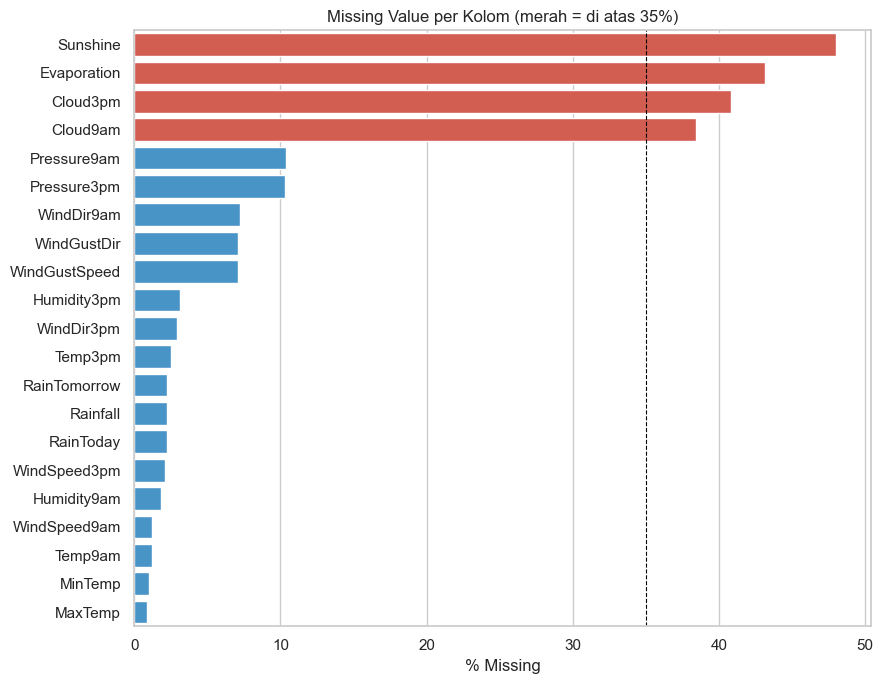

In [16]:
# Visualisasikan kolom yang memiliki missing value.
plot_tab = null_tab[null_tab.n_missing > 0]

plt.figure(figsize=(9, 7))
sns.barplot(x=plot_tab["pct"], y=plot_tab.index, hue=plot_tab["pct"] > 35,
            palette={True: "#e74c3c", False: "#3498db"}, legend=False)
plt.axvline(35, color="k", ls="--", lw=0.8)
plt.xlabel("% Missing")
plt.ylabel("")
plt.title("Missing Value per Kolom (merah = di atas 35%)")
plt.tight_layout()
plt.show()

### Cara Membaca Grafik Missing

- Batang biru = missing di bawah 35%.
- Batang merah = missing di atas 35%.
- Garis hitam adalah batas 35% yang dipakai tim sebagai sinyal "perlu diperhatikan".

Kolom dengan missing tinggi belum tentu langsung dibuang. Kita harus cek dulu:
apakah missing-nya punya pola, dan apakah kolom itu masih punya sinyal prediksi.

In [17]:
# Hitung jumlah baris lengkap tanpa satu pun NaN.
n_null_row = df.isna().sum(axis=1)

n_lengkap = int((n_null_row == 0).sum())
n_bolong = int((n_null_row > 0).sum())

print(f"Baris lengkap (0 null) : {n_lengkap:,} ({n_lengkap/len(df)*100:.1f}%)")
print(f"Baris punya >=1 null   : {n_bolong:,} ({n_bolong/len(df)*100:.1f}%)")
print(f"Kalau dropna() semua   : sisa {len(df.dropna()):,} baris")

Baris lengkap (0 null) : 56,420 (38.8%)
Baris punya >=1 null   : 89,040 (61.2%)
Kalau dropna() semua   : sisa 56,420 baris


### Kenapa Tidak Langsung `dropna()`?

Jika semua baris yang memiliki satu saja NaN dibuang, dataset tinggal sekitar 56.420 baris
dari 145.460 baris. Kita kehilangan lebih dari 60% data.

Kehilangan data sebesar itu berbahaya karena:

- sampel lokasi dan waktu menjadi tidak mewakili,
- pola cuaca ekstrem bisa hilang,
- model menjadi kurang stabil.

Jadi keputusan drop harus selektif, bukan sapu jagat.

### Apakah Missing-nya Acak atau Struktural?

Jika missing tersebar acak, imputasi sering masuk akal.
Jika missing terkonsentrasi di lokasi atau tahun tertentu, kemungkinan besar alat ukurnya
memang tidak tersedia. Artinya NaN berarti **"tidak diukur"**, bukan "hilang misterius".

Kita cek kolom dengan missing tinggi:

- `Sunshine`
- `Evaporation`
- `Cloud9am`
- `Cloud3pm`
- `Pressure9am`

In [18]:
# Kelompokkan kolom dengan missing tinggi lalu cek hubungannya dengan target.
HIGH_MISS = ["Sunshine", "Evaporation", "Cloud9am", "Cloud3pm", "Pressure9am"]
HIGH_MISS = [c for c in HIGH_MISS if c in df.columns]

baris = []
for loc in df["Location"].unique():
    subset = df[df["Location"] == loc]
    row = {"Location": loc}
    for col in HIGH_MISS:
        row[col] = round(subset[col].isna().mean() * 100, 0)
    baris.append(row)

by_loc = pd.DataFrame(baris).set_index("Location")
print(f"Missing per lokasi sudah dihitung untuk {len(by_loc)} lokasi.")

Missing per lokasi sudah dihitung untuk 49 lokasi.


In [19]:
# Tampilkan stasiun dengan missing Sunshine tertinggi.
display(by_loc.sort_values("Sunshine", ascending=False).head(12))

print("Lokasi yang 100% tidak pernah melapor:")
for col in HIGH_MISS:
    never = by_loc.index[by_loc[col] == 100].tolist()
    contoh = never[:6]
    suffix = " ..." if len(never) > 6 else ""
    print(f"  {col:12s}: {len(never):2d} lokasi  {contoh}{suffix}")

,Sunshine,Evaporation,Cloud9am,Cloud3pm,Pressure9am
Location,,,,,
Albury,100.0,100.0,58.0,53.0,0.0
BadgerysCreek,100.0,100.0,100.0,100.0,6.0
Penrith,100.0,100.0,100.0,100.0,100.0
NorahHead,100.0,100.0,100.0,100.0,1.0
Newcastle,100.0,100.0,8.0,31.0,100.0
Wollongong,100.0,100.0,56.0,53.0,2.0
Tuggeranong,100.0,100.0,100.0,100.0,0.0
MountGinini,100.0,100.0,100.0,100.0,100.0
Richmond,100.0,46.0,80.0,81.0,1.0


Lokasi yang 100% tidak pernah melapor:
  Sunshine    : 19 lokasi  ['Albury', 'BadgerysCreek', 'Newcastle', 'NorahHead', 'Penrith', 'Richmond'] ...
  Evaporation : 16 lokasi  ['Albury', 'BadgerysCreek', 'Newcastle', 'NorahHead', 'Penrith', 'Wollongong'] ...
  Cloud9am    : 12 lokasi  ['BadgerysCreek', 'NorahHead', 'Penrith', 'Tuggeranong', 'MountGinini', 'Nhil'] ...
  Cloud3pm    : 12 lokasi  ['BadgerysCreek', 'NorahHead', 'Penrith', 'Tuggeranong', 'MountGinini', 'Nhil'] ...
  Pressure9am :  4 lokasi  ['Newcastle', 'Penrith', 'MountGinini', 'SalmonGums']


In [20]:
# Periksa apakah missing value terkonsentrasi pada tahun tertentu.
df_year = df.copy()
df_year["Year"] = df_year["Date"].dt.year
by_year = df_year.groupby("Year")[HIGH_MISS + ["RainTomorrow"]].apply(lambda x: (x.isna().mean() * 100).round(1))
display(by_year)

,Sunshine,Evaporation,Cloud9am,Cloud3pm,Pressure9am,RainTomorrow
Year,,,,,,
2007,0.0,0.0,0.0,0.0,0.0,0.0
2008,14.2,14.9,16.7,17.1,4.2,1.1
2009,36.6,34.0,33.2,34.6,10.4,1.2
2010,37.1,35.3,33.0,33.9,9.7,2.2
2011,39.3,37.6,37.9,39.4,10.1,1.8
2012,42.4,39.3,38.1,39.8,8.9,2.4
2013,46.1,39.2,41.2,41.5,8.4,1.9
2014,51.2,46.0,40.0,40.4,11.3,2.7
2015,52.8,48.6,39.7,42.1,13.4,3.7


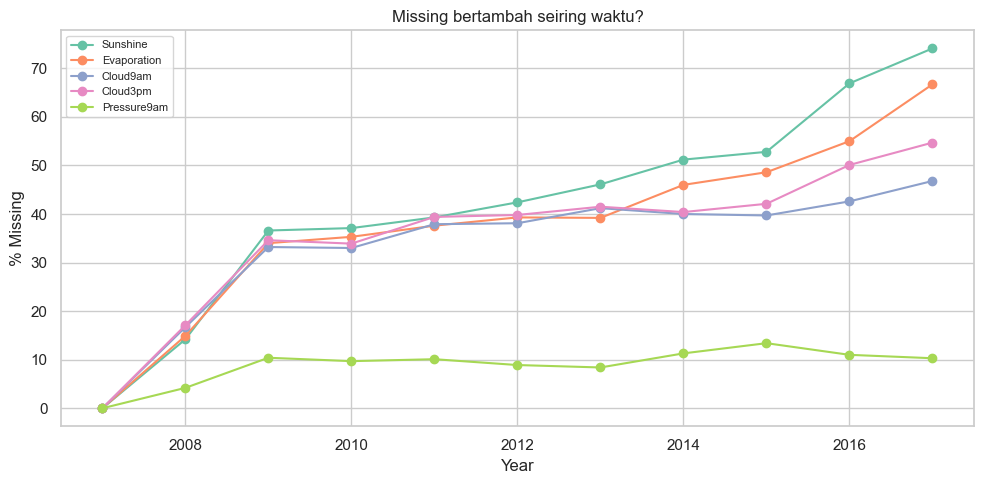

In [21]:
# Plot missing rate per tahun untuk kolom penting.
ax = by_year[HIGH_MISS].plot(marker="o", figsize=(10, 5))
ax.set_ylabel("% Missing")
ax.set_title("Missing bertambah seiring waktu?")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

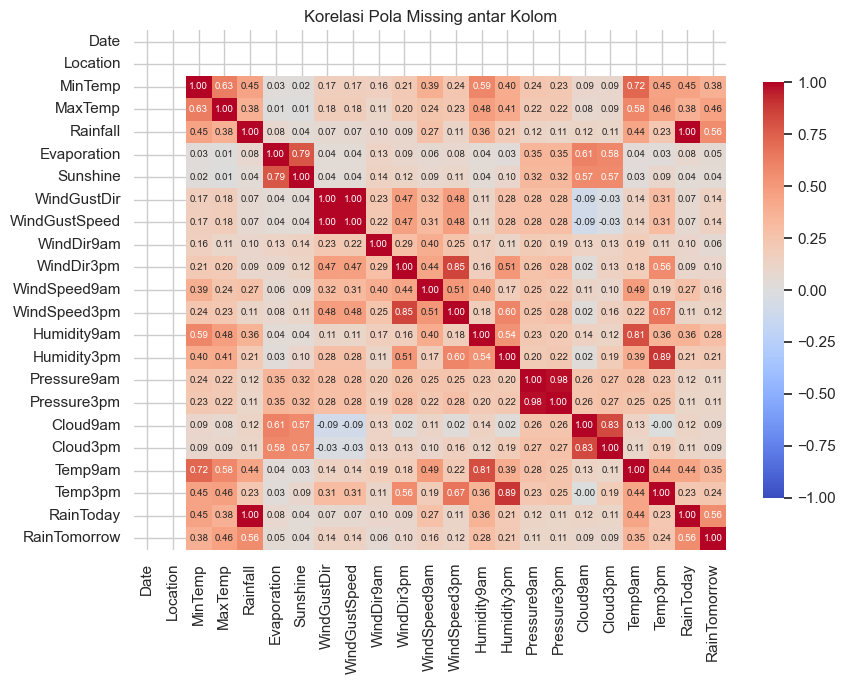

In [22]:
# Tampilkan pola missing value per lokasi dan kolom.
plt.figure(figsize=(9, 7))
sns.heatmap(df.isna().corr(), cmap="coolwarm", center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"shrink": 0.8}, vmin=-1, vmax=1)
plt.title("Korelasi Pola Missing antar Kolom")
plt.tight_layout()
plt.show()

### Cara Membaca Pola Missing

- Beberapa lokasi memiliki missing 100% untuk `Sunshine`, `Cloud`, atau `Evaporation`.
- Artinya alat ukur atau pencatatan memang tidak tersedia di lokasi itu.
- Heatmap korelasi missing menunjukkan kolom tertentu kosong bersamaan.
- Kesimpulan: missing value di dataset ini **struktural**, bukan acak.

Karena struktural, imputasi median global berbahaya. Contoh: mengisi `Sunshine`
dengan median nasional untuk stasiun yang tidak pernah mengukur sunshine akan menciptakan
informasi palsu.

### Dampak & Sinyal Prediktif Kolom High-Missing

Sebelum memutuskan buang atau pertahankan kolom, kita ukur dua hal:

1. **Dampak data hilang**: berapa baris dan lokasi hilang jika kolom high-missing dibuang.
2. **Sinyal prediktif**: seberapa kuat korelasi kolom itu dengan target.

Kolom yang missing-nya tinggi **dan** sinyalnya lemah adalah kandidat utama untuk dibuang.

In [23]:
# Simulasi dampak dropna jika kolom missing tinggi dibuang.
rows = []
for col in HIGH_MISS:
    ada = df[col].notna()
    rows.append({
        "kolom": col,
        "baris_tersisa": int(ada.sum()),
        "pct_data_hilang": round((1 - ada.mean()) * 100, 1),
        "lokasi_tersisa": df.loc[ada, "Location"].nunique(),
        "lokasi_hilang": df.loc[~ada, "Location"].nunique(),
    })

impact = pd.DataFrame(rows).set_index("kolom")
display(impact)

,baris_tersisa,pct_data_hilang,lokasi_tersisa,lokasi_hilang
kolom,,,,
Sunshine,75625,48.0,30,49
Evaporation,82670,43.2,33,49
Cloud9am,89572,38.4,37,47
Cloud3pm,86102,40.8,37,48
Pressure9am,130395,10.4,45,45


In [24]:
# Cek baris tersisa bila memakai complete-case pada kolom penting.
sisa = df.dropna(subset=HIGH_MISS)

print(f"Total lokasi dataset: {df['Location'].nunique()}")
print(f"Baris sisa jika drop semua high-missing: {len(sisa):,} ({len(sisa)/len(df)*100:.1f}%)")
print(f"Lokasi sisa: {sisa['Location'].nunique()}")

Total lokasi dataset: 49
Baris sisa jika drop semua high-missing: 62,471 (42.9%)
Lokasi sisa: 27


In [25]:
# Bandingkan rata-rata fitur saat target hujan dan tidak hujan.
d = df.dropna(subset=["RainTomorrow"]).copy()
d["y"] = (d["RainTomorrow"] == "Yes").astype(int)

rows = []
for col in HIGH_MISS:
    ada = d[col].notna()
    r = d.loc[ada, [col, "y"]].corr().iloc[0, 1]
    rows.append({"kolom": col, "korelasi_dgn_target": round(r, 3), "n_baris_dipakai": int(ada.sum())})

signal = pd.DataFrame(rows).set_index("kolom")
signal = signal.reindex(signal["korelasi_dgn_target"].abs().sort_values(ascending=False).index)
display(signal)

,korelasi_dgn_target,n_baris_dipakai
kolom,,
Sunshine,-0.451,74377
Cloud3pm,0.382,85099
Cloud9am,0.317,88536
Pressure9am,-0.246,128179
Evaporation,-0.119,81350


### Cara Membaca Sinyal Prediktif

- Korelasi mendekati 0 = sinyal linear lemah.
- Korelasi makin jauh dari 0 = sinyal makin kuat, baik positif maupun negatif.
- `Sunshine` dan `Cloud` missing tinggi, tetapi sinyalnya kuat.
- `Evaporation` missing tinggi dan sinyalnya paling lemah.

Jadi keputusan tidak boleh hanya melihat persentase missing.

### Benchmark Eksperimen: Strategi Missing Value (A–E)

Sebelum memutuskan penanganan missing, tim menguji 5 strategi dengan **setup yang identik**
supaya perbandingannya adil:

- **Model**: XGBoost — `n_estimators=400`, `max_depth=6`, `learning_rate=0.08`,
  `subsample=0.9`, `colsample_bytree=0.9`, `random_state=42` (sama dengan `src/train.py`).
- **Data**: hanya baris yang punya target (142.193 baris), diurutkan berdasarkan `Date`.
- **Split**: time-based 80/20 **tanpa shuffle** (sama seperti Bagian 11).
- **Kategorikal**: imputasi modus + one-hot encoding (`handle_unknown="ignore"`).
- **Numerik**: dibiarkan NaN (strategi A/B/C) atau diimputasi median (strategi D/E).
- **Metrik**: ROC-AUC dan F1 (threshold 0,5) pada data test.

Strategi E menambahkan `MissingIndicator` — kolom penanda "nilai ini semula kosong".

> Sel di bawah ini **bisa dijalankan ulang oleh siapa pun** untuk mereproduksi angka
> pada tabel keputusan. Runtime ± 40–60 detik (5× training XGBoost).

In [26]:
# Benchmark 5 strategi penanganan missing value (XGBoost, time-based split).
import time
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, f1_score

XGB_PARAMS = dict(n_estimators=400, max_depth=6, learning_rate=0.08,
                  subsample=0.9, colsample_bytree=0.9, eval_metric="logloss",
                  tree_method="hist", n_jobs=-1, random_state=42)
CAT_COLS = ["Location", "WindGustDir", "WindDir9am", "WindDir3pm", "RainToday"]

# Data benchmark: baris bertarget saja, urut waktu (df di titik ini belum dibersihkan
# dari baris tanpa RainTomorrow, jadi difilter dulu di sini).
bm = df.dropna(subset=["RainTomorrow"]).sort_values("Date").reset_index(drop=True)
X_bm = bm.drop(columns=["Date", "RainTomorrow"])
y_bm = bm["RainTomorrow"].eq("Yes").astype(int)

split_idx = int(len(X_bm) * 0.8)
X_tr, X_te = X_bm.iloc[:split_idx], X_bm.iloc[split_idx:]
y_tr, y_te = y_bm.iloc[:split_idx], y_bm.iloc[split_idx:]
spw = (y_tr == 0).sum() / (y_tr == 1).sum()

def benchmark(name, drop_cols=None, impute_num=False, add_indicator=False):
    """Latih XGBoost dengan satu strategi missing value, kembalikan metrik test."""
    d = X_bm.drop(columns=drop_cols or [])
    num_cols = [c for c in d.columns if c not in CAT_COLS]
    num_pipe = (SimpleImputer(strategy="median", add_indicator=add_indicator)
                if impute_num else "passthrough")
    pre = ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), CAT_COLS),
    ])
    model = Pipeline([
        ("pre", pre),
        ("clf", XGBClassifier(scale_pos_weight=spw, **XGB_PARAMS)),
    ])
    t0 = time.time()
    model.fit(X_tr, y_tr)
    dt = time.time() - t0
    proba = model.predict_proba(X_te)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return dict(Strategi=name,
                ROC_AUC=round(roc_auc_score(y_te, proba), 4),
                F1=round(f1_score(y_te, pred), 4),
                Detik=round(dt, 1))

hasil = [
    benchmark("A. Semua kolom, NaN native"),
    benchmark("B. Tanpa Evaporation, NaN native", drop_cols=["Evaporation"]),
    benchmark("C. Drop semua high-missing",
              drop_cols=["Evaporation", "Sunshine", "Cloud9am", "Cloud3pm", "Pressure9am"]),
    benchmark("D. Imputasi median global", impute_num=True),
    benchmark("E. Imputasi median + indikator", impute_num=True, add_indicator=True),
]
tabel_benchmark = pd.DataFrame(hasil).set_index("Strategi")
display(tabel_benchmark)
print("Kesimpulan: B setara baseline (selisih < 0.001) dengan 1 kolom lebih ringan;")
print("C turun (kehilangan sinyal); D/E tidak lebih baik dari baseline.")

,ROC_AUC,F1,Detik
Strategi,,,
"A. Semua kolom, NaN native",0.8866,0.6569,6.4
"B. Tanpa Evaporation, NaN native",0.8863,0.6559,6.4
C. Drop semua high-missing,0.8835,0.6490,6.2
D. Imputasi median global,0.8844,0.6545,3.9
E. Imputasi median + indikator,0.8865,0.6554,4.2


Kesimpulan: B setara baseline (selisih < 0.001) dengan 1 kolom lebih ringan;
C turun (kehilangan sinyal); D/E tidak lebih baik dari baseline.


### Keputusan Tim: Penanganan Missing Value

**Apa yang ditemukan?**
Missing value bersifat struktural. Beberapa stasiun tidak pernah melaporkan `Sunshine`,
`Cloud`, `Evaporation`, dan sebagian `Pressure`.

**Benchmark strategi missing value** (angka di bawah = output sel benchmark di atas, reproducible):

| Strategi | ROC-AUC | F1 | Catatan |
|---|---|---|---|
| A. Semua kolom, NaN native | 0.8866 | 0.6569 | baseline |
| B. Tanpa `Evaporation`, NaN native | 0.8863 | 0.6559 | ≈ baseline (selisih < 0.001), lebih ringan & cepat |
| C. Drop semua kolom high-missing | 0.8835 | 0.6490 | ROC & F1 turun → kehilangan sinyal |
| D. Imputasi median global | 0.8844 | 0.6545 | tidak lebih baik dari baseline |
| E. Imputasi + kolom indikator | 0.8865 | 0.6554 | setara baseline, tidak menambah sinyal |

**Keputusan**: buang `Evaporation` saja (strategi B) — performa setara baseline dengan
fitur lebih ringan. Kolom high-missing lain dipertahankan karena C terbukti turun.
NaN numerik dibiarkan (XGBoost menanganinya secara native); imputasi global tidak dipakai
karena tidak terbukti lebih baik.

### Decision Log Missing Value

| Apa | Kenapa | Dampaknya |
|---|---|---|
| Drop `Evaporation` | missing 43%, sinyal paling lemah, redundan dengan `Rainfall`/`Sunshine` | data lebih ringan tanpa kehilangan sinyal penting |
| Drop 3.267 baris tanpa `RainTomorrow` | supervised learning butuh label target | dataset modeling menjadi 142.193 baris |
| Biarkan NaN sisa | XGBoost menangani NaN native; benchmark imputasi global tidak lebih baik | tidak menciptakan nilai palsu |
| Tidak pakai kolom indikator missing | benchmark tidak menunjukkan tambahan sinyal | pipeline lebih sederhana |
| Imputasi hanya di dalam pipeline LR/RF | scaler/imputer hanya boleh belajar dari train | mencegah leakage |
| `Location` tetap dipertahankan | aplikasi memakai 49 lokasi; membuang lokasi mengurangi cakupan | model tetap bisa dipakai lintas stasiun |

In [27]:
# Catat jumlah baris sebelum cleaning tahap 1.
n_sebelum = len(df)
c_sebelum = df.shape[1]

df = df.drop(columns=["Evaporation"])
print(f"Kolom sebelum : {c_sebelum}")
print(f"Kolom sesudah : {df.shape[1]}")
print(f"Baris tetap   : {len(df):,}")

Kolom sebelum : 23
Kolom sesudah : 22
Baris tetap   : 145,460


In [28]:
# Buang baris tanpa target karena supervised learning butuh label.
df = df.dropna(subset=["RainTomorrow"]).copy()
n_dibuang = n_sebelum - len(df)

print(f"Baris sebelum            : {n_sebelum:,}")
print(f"Baris sesudah            : {len(df):,}")
print(f"Baris target NaN dibuang : {n_dibuang:,}")

Baris sebelum            : 145,460
Baris sesudah            : 142,193
Baris target NaN dibuang : 3,267


In [29]:
# Hitung ulang total NaN setelah cleaning tahap 1.
total_nan_stage1 = int(df.isna().sum().sum())

print(f"Bentuk setelah cleaning tahap 1: {len(df):,} baris x {df.shape[1]} kolom")
print(f"Total NaN sisa                 : {total_nan_stage1:,} ({total_nan_stage1/df.size*100:.1f}%)")
print("\nTarget setelah cleaning:")
print(df["RainTomorrow"].value_counts(normalize=True).mul(100).round(1))

Bentuk setelah cleaning tahap 1: 142,193 baris x 22 kolom
Total NaN sisa                 : 255,716 (8.2%)

Target setelah cleaning:
RainTomorrow
No     77.6
Yes    22.4
Name: proportion, dtype: float64


### Cara Membaca Hasil Cleaning Tahap 1

- `Evaporation` sudah dibuang.
- Baris tanpa target sudah dibuang.
- Bentuk data menjadi 142.193 baris.
- NaN lain sengaja dibiarkan dulu.
- Penanganan NaN final berbeda per model:
  - XGBoost: NaN native.
  - RandomForest/LogisticRegression: imputasi di dalam pipeline.

## 7. Validitas Data

> **Tahapan CRISP-DM:** Fase 3 — Data Preparation

**Validitas data** berarti nilai masuk akal menurut definisi kolom dan hukum fisika.
Contoh: kelembapan relatif tidak mungkin 150%, dan suhu jam 3 sore tidak mungkin jauh
di atas suhu maksimum harian.

Bedakan dua hal:

- **Missing value** = nilai tidak ada.
- **Nilai tidak valid** = nilai ada, tetapi mustahil atau sangat mencurigakan.

Pada bagian ini, baris yang NaN **tidak dihitung sebagai pelanggaran**.
Kita hanya memeriksa baris yang kolomnya benar-benar terisi.

### Aturan Validitas yang Dipakai

| Aturan | Dasar |
|---|---|
| `MinTemp <= MaxTemp` | suhu minimum tidak mungkin lebih besar dari maksimum |
| `Temp9am` di antara `MinTemp` dan `MaxTemp` | pembacaan jam 9 harus berada dalam rentang hari itu |
| `Temp3pm` di antara `MinTemp` dan `MaxTemp` | pembacaan jam 3 harus berada dalam rentang hari itu |
| `Humidity` 0–100 | kelembapan relatif dibatasi definisi persen |
| `Cloud` 0–9 | satuan oktaf |
| `Rainfall >= 0` | curah hujan tidak mungkin negatif |
| `Sunshine` 0–24 jam | tidak mungkin lebih lama dari satu hari |
| `Pressure` 950–1060 hPa | rentang realistis catatan Australia |
| `WindGustSpeed >= WindSpeed9am/3pm` | gust adalah hembusan tertinggi |
| `WindSpeed9am <= 100` | rata-rata 10 menit di atas 100 km/jam sangat mencurigakan |
| Arah angin = 16 kompas | label harus valid |
| `RainToday == (Rainfall > 1)` | `RainToday` diturunkan dari `Rainfall` |

**Mask** = kolom boolean `True`/`False` untuk menandai baris yang melanggar aturan.

In [30]:
# Definisikan enam belas arah angin kompas yang valid.
COMPASS = {
    "N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
    "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW",
}
print(f"Jumlah titik kompas valid: {len(COMPASS)}")

Jumlah titik kompas valid: 16


In [31]:
# Cek 1: MinTemp tidak boleh lebih besar dari MaxTemp
terisi = df[["MinTemp", "MaxTemp"]].notna().all(axis=1)
syarat = df["MinTemp"] <= df["MaxTemp"]
langgar = terisi & ~syarat.fillna(False)
print(f"MinTemp <= MaxTemp | dicek={int(terisi.sum()):,} | melanggar={int(langgar.sum()):,}")

# Cek 2: Temp9am harus berada di antara MinTemp dan MaxTemp
terisi = df[["Temp9am", "MinTemp", "MaxTemp"]].notna().all(axis=1)
syarat = df["Temp9am"].between(df["MinTemp"], df["MaxTemp"])
langgar9am = terisi & ~syarat.fillna(False)
print(f"Temp9am rentang harian | dicek={int(terisi.sum()):,} | melanggar={int(langgar9am.sum()):,}")

MinTemp <= MaxTemp | dicek=141,322 | melanggar=0
Temp9am rentang harian | dicek=140,780 | melanggar=16


In [32]:
# Cek 3: Temp3pm harus berada di antara MinTemp dan MaxTemp
terisi = df[["Temp3pm", "MinTemp", "MaxTemp"]].notna().all(axis=1)
syarat = df["Temp3pm"].between(df["MinTemp"], df["MaxTemp"])
langgar3pm = terisi & ~syarat.fillna(False)
print(f"Temp3pm rentang harian | dicek={int(terisi.sum()):,} | melanggar={int(langgar3pm.sum()):,}")

Temp3pm rentang harian | dicek=138,994 | melanggar=1,218


In [33]:
# Cek 4: kelembapan relatif harus 0-100 persen
terisi = df[["Humidity9am", "Humidity3pm"]].notna().all(axis=1)
syarat = df["Humidity9am"].between(0, 100) & df["Humidity3pm"].between(0, 100)
langgar = terisi & ~syarat.fillna(False)
print(f"Humidity 0-100% | dicek={int(terisi.sum()):,} | melanggar={int(langgar.sum()):,}")

# Cek 5: cloud dalam oktaf 0-9
terisi = df[["Cloud9am", "Cloud3pm"]].notna().all(axis=1)
syarat = df["Cloud9am"].between(0, 9) & df["Cloud3pm"].between(0, 9)
langgar = terisi & ~syarat.fillna(False)
print(f"Cloud 0-9 oktaf | dicek={int(terisi.sum()):,} | melanggar={int(langgar.sum()):,}")

Humidity 0-100% | dicek=137,907 | melanggar=0
Cloud 0-9 oktaf | dicek=81,119 | melanggar=0


In [34]:
# Cek 6: curah hujan tidak boleh negatif
terisi = df[["Rainfall"]].notna().all(axis=1)
syarat = df["Rainfall"] >= 0
langgar = terisi & ~syarat.fillna(False)
print(f"Rainfall >= 0 | dicek={int(terisi.sum()):,} | melanggar={int(langgar.sum()):,}")

# Cek 7: sunshine tidak mungkin lebih dari 24 jam
terisi = df[["Sunshine"]].notna().all(axis=1)
syarat = df["Sunshine"].between(0, 24)
langgar = terisi & ~syarat.fillna(False)
print(f"Sunshine 0-24 jam | dicek={int(terisi.sum()):,} | melanggar={int(langgar.sum()):,}")

Rainfall >= 0 | dicek=140,787 | melanggar=0
Sunshine 0-24 jam | dicek=74,377 | melanggar=0


In [35]:
# Cek 8: tekanan udara normal
terisi = df[["Pressure9am", "Pressure3pm"]].notna().all(axis=1)
syarat = df["Pressure9am"].between(950, 1060) & df["Pressure3pm"].between(950, 1060)
langgar = terisi & ~syarat.fillna(False)
print(f"Pressure 950-1060 hPa | dicek={int(terisi.sum()):,} | melanggar={int(langgar.sum()):,}")

# Cek 9: gust harus >= kecepatan angin rata-rata
terisi = df[["WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"]].notna().all(axis=1)
rata_angin = df[["WindSpeed9am", "WindSpeed3pm"]].max(axis=1)
syarat = df["WindGustSpeed"] >= rata_angin
mask_gust_invalid = terisi & ~syarat.fillna(False)
print(f"Gust >= angin rata-rata | dicek={int(terisi.sum()):,} | melanggar={int(mask_gust_invalid.sum()):,}")

Pressure 950-1060 hPa | dicek=127,989 | melanggar=0
Gust >= angin rata-rata | dicek=132,349 | melanggar=5


In [36]:
# Cek 10: kecepatan angin pagi tidak di atas 100 km/jam
terisi = df[["WindSpeed9am"]].notna().all(axis=1)
syarat = df["WindSpeed9am"] <= 100
mask_wind9am_invalid = terisi & ~syarat.fillna(False)
print(f"WindSpeed9am <= 100 km/jam | dicek={int(terisi.sum()):,} | melanggar={int(mask_wind9am_invalid.sum()):,}")

# Cek 11: arah angin harus salah satu dari 16 titik kompas
terisi = df[["WindGustDir", "WindDir9am", "WindDir3pm"]].notna().all(axis=1)
syarat = df["WindGustDir"].isin(COMPASS) & df["WindDir9am"].isin(COMPASS) & df["WindDir3pm"].isin(COMPASS)
langgar = terisi & ~syarat.fillna(False)
print(f"Arah 16 kompas | dicek={int(terisi.sum()):,} | melanggar={int(langgar.sum()):,}")

WindSpeed9am <= 100 km/jam | dicek=140,845 | melanggar=1
Arah 16 kompas | dicek=124,668 | melanggar=0


In [37]:
# Cek 12: RainToday harus cocok dengan aturan Rainfall > 1 mm
terisi = df[["RainToday", "Rainfall"]].notna().all(axis=1)
label_hujan = df["RainToday"] == "Yes"
aturan_hujan = df["Rainfall"] > 1
langgar = terisi & ~(label_hujan == aturan_hujan).fillna(False)
print(f"RainToday == (Rainfall > 1) | dicek={int(terisi.sum()):,} | melanggar={int(langgar.sum()):,}")

RainToday == (Rainfall > 1) | dicek=140,787 | melanggar=0


### Ringkasan Audit Validitas Mentah

| Aturan | Baris dicek | Melanggar |
|---|---:|---:|
| `MinTemp <= MaxTemp` | 141.322 | 0 |
| `Temp9am` rentang harian | 140.780 | 16 |
| `Temp3pm` rentang harian | 138.994 | 1.218 |
| Humidity 0–100% | 137.907 | 0 |
| Cloud 0–9 oktaf | 81.119 | 0 |
| `Rainfall >= 0` | 140.787 | 0 |
| `Sunshine` 0–24 jam | 74.377 | 0 |
| Pressure 950–1060 hPa | 127.989 | 0 |
| Gust >= angin rata-rata | 132.349 | 5 |
| `WindSpeed9am <= 100` | 140.845 | 1 |
| Arah 16 kompas | 124.668 | 0 |
| `RainToday == (Rainfall > 1)` | 140.787 | 0 |

Cara membaca:

- `dicek` = baris yang semua kolom terkaitnya terisi.
- `melanggar` = baris yang aturannya tidak terpenuhi.
- NaN tidak dihitung sebagai pelanggaran.
- Mayoritas aturan fisik sudah bersih.
- Masalah utama ada di rentang suhu sore/pagi, gust, dan satu nilai angin ekstrem.

### Kenapa `Temp3pm` Perlu Dianalisis Lebih Dalam?

`MinTemp` dan `MaxTemp` adalah ekstrem selama 24 jam.
`Temp3pm` adalah pembacaan sesaat jam 3 sore, bisa berasal dari sensor atau lokasi alat
yang sedikit berbeda, dan dibulatkan 0,1°C.

Jadi pelanggaran kecil belum tentu error sensor. Bisa jadi hanya artefak metode ukur.
Kita perlu melihat **berapa besar selisihnya**, bukan hanya berapa banyak barisnya.

In [38]:
# Hitung selisih Temp3pm dari batas MinTemp/MaxTemp saat melanggar rentang.
ada_suhu = df[["MinTemp", "MaxTemp", "Temp3pm"]].notna().all(axis=1)
terlalu_dingin = ada_suhu & (df["Temp3pm"] < df["MinTemp"])
terlalu_panas = ada_suhu & (df["Temp3pm"] > df["MaxTemp"])
selisih_bawah = (df["MinTemp"] - df["Temp3pm"]).where(terlalu_dingin)
selisih_atas = (df["Temp3pm"] - df["MaxTemp"]).where(terlalu_panas)
selisih_temp3pm = pd.concat([selisih_bawah, selisih_atas], axis=1).max(axis=1).dropna()

print(f"Jumlah pelanggaran rentang Temp3pm: {len(selisih_temp3pm):,} baris")
print(selisih_temp3pm.describe().round(2).to_string())

Jumlah pelanggaran rentang Temp3pm: 1,218 baris
count    1218.00
mean        1.28
std         1.22
min         0.10
25%         0.40
50%         0.90
75%         1.80
max         8.80


In [39]:
# Lihat sebaran selisih suhu dan sensitivitas pilihan toleransi.
print("Kuantil selisih:", selisih_temp3pm.quantile([.5, .9, .99]).round(2).to_dict())
print("\nSensitivitas pilihan toleransi:")
for tol in [0.0, 0.5, 1.0, 2.0]:
    terlalu_dingin = selisih_bawah > tol
    terlalu_panas = selisih_atas > tol
    n = int((terlalu_dingin | terlalu_panas).sum())
    print(f"  toleransi {tol:.1f} C -> {n:5d} baris dianggap error ({n/len(df)*100:.2f}%)")

Kuantil selisih: {0.5: 0.9, 0.9: 2.93, 0.99: 5.6}

Sensitivitas pilihan toleransi:
  toleransi 0.0 C ->  1218 baris dianggap error (0.86%)
  toleransi 0.5 C ->   801 baris dianggap error (0.56%)
  toleransi 1.0 C ->   539 baris dianggap error (0.38%)
  toleransi 2.0 C ->   243 baris dianggap error (0.17%)


In [40]:
# Tampilkan lima pelanggaran suhu sore terbesar untuk inspeksi manual.
lima_terbesar = selisih_temp3pm.nlargest(5)
kolom = ["Date", "Location", "MinTemp", "MaxTemp", "Temp3pm"]
display(df.loc[lima_terbesar.index, kolom].assign(selisih_C=lima_terbesar.round(1).values))

,Date,Location,MinTemp,MaxTemp,Temp3pm,selisih_C
2397,2012-02-05,Ballarat,21.5,26.3,12.7,8.8
60237,2017-02-12,MountGinini,15.8,18.8,8.2,7.6
11368,2016-10-17,Sydney,21.7,22.4,14.5,7.2
70576,2017-02-12,WaggaWagga,21.7,27.6,15.2,6.5
129249,2016-12-26,Melbourne,25.4,29.3,18.9,6.5


In [41]:
# Lakukan pemeriksaan serupa untuk Temp9am.
ada_suhu9 = df[["MinTemp", "MaxTemp", "Temp9am"]].notna().all(axis=1)
dingin9 = ada_suhu9 & (df["Temp9am"] < df["MinTemp"])
panas9 = ada_suhu9 & (df["Temp9am"] > df["MaxTemp"])
bawah9 = (df["MinTemp"] - df["Temp9am"]).where(dingin9)
atas9 = (df["Temp9am"] - df["MaxTemp"]).where(panas9)
selisih_temp9am = pd.concat([bawah9, atas9], axis=1).max(axis=1).dropna()

print(f"Temp9am raw    : {len(selisih_temp9am):,} baris")
print(f"Selisih <= 1 C : {int((selisih_temp9am <= 1).sum()):,} baris")
print(f"Selisih > 1 C  : {int((selisih_temp9am > 1).sum()):,} baris")
print(f"Median / Maks  : {selisih_temp9am.median():.2f} C / {selisih_temp9am.max():.2f} C")

Temp9am raw    : 16 baris


Selisih <= 1 C : 14 baris
Selisih > 1 C  : 2 baris
Median / Maks  : 0.40 C / 2.20 C


### Cara Membaca Analisis Suhu

- `Temp3pm` raw: 1.218 baris di luar rentang.
- Median selisih hanya 0,9°C; 25% kasus bahkan ≤ 0,4°C.
- Mayoritas kecil ini lebih mirip artefak pembulatan/perbedaan sensor, bukan data rusak.
- Ekor distribusinya sampai 8,8°C; itu jelas tidak bisa dijelaskan pembulatan.
- Sensitivitas toleransi:
  - 0,0°C → 1.218 baris error
  - 0,5°C → 801 baris error
  - 1,0°C → 539 baris error
  - 2,0°C → 243 baris error

Tim memilih toleransi **1,0°C** karena memisahkan selisih kecil yang wajar dari ekor
pelanggaran yang jelas rusak.

- `Temp9am` raw: 16 baris.
- Selisih ≤ 1°C: 14 baris → dibiarkan.
- Selisih > 1°C: 2 baris → NaN.

In [42]:
# Tampilkan baris dengan gust lebih kecil dari angin rata-rata.
kolom = ["Date", "Location", "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"]
display(df.loc[mask_gust_invalid, kolom])
print(f"Jumlah: {int(mask_gust_invalid.sum()):,} baris")

,Date,Location,WindGustSpeed,WindSpeed9am,WindSpeed3pm
5294,2010-09-03,Richmond,24.0,33.0,4.0
10773,2012-11-09,CoffsHarbour,26.0,28.0,4.0
22184,2011-10-13,PearceRAAF,20.0,24.0,30.0
105132,2008-12-04,Darwin,30.0,9.0,33.0
125549,2014-04-03,Darwin,15.0,6.0,17.0


Jumlah: 5 baris


### Cara Membaca Anomali Gust

`WindGustSpeed` adalah hembusan tertinggi dalam 24 jam.
Secara definisi, gust tidak mungkin lebih kecil daripada kecepatan angin rata-rata
pada jam 9 pagi atau jam 3 sore.

Gap-nya kecil (sekitar 2–9 km/j), tetapi ini tetap mustahil secara definisi.
Berbeda dengan kasus suhu, ini tidak bisa dijelaskan oleh perbedaan sensor.
Keputusan: ubah `WindGustSpeed` pada 5 baris itu menjadi NaN.

In [43]:
# Tampilkan nilai WindSpeed9am terbesar beserta persentilnya.
kolom = ["Date", "Location", "WindSpeed9am", "WindSpeed3pm", "WindGustSpeed", "Rainfall"]
display(df.nlargest(8, "WindSpeed9am")[kolom])
print("Persentil WindSpeed9am:", df["WindSpeed9am"].quantile([.5, .99, .999]).round(1).to_dict())

,Date,Location,WindSpeed9am,WindSpeed3pm,WindGustSpeed,Rainfall
1767,2017-01-18,Newcastle,130.0,NaN,NaN,0.0
1768,2015-04-21,NorahHead,87.0,74.0,135.0,61.4
1769,2010-09-05,Wollongong,87.0,30.0,126.0,3.6
1770,2009-09-23,Newcastle,83.0,83.0,NaN,0.0
1771,2009-09-26,Newcastle,74.0,65.0,NaN,0.0
1772,2009-09-27,Newcastle,74.0,56.0,NaN,0.0
1773,2010-09-05,Newcastle,74.0,19.0,NaN,1.2
1774,2016-07-13,Newcastle,74.0,NaN,NaN,0.0


Persentil WindSpeed9am:

 {0.5: 13.0, 0.99: 39.0, 0.999: 54.0}


In [44]:
# Lihat konteks sekitar nilai angin ekstrem di Newcastle.
idx = df.index[(df["Location"] == "Newcastle") & (df["WindSpeed9am"] > 100)][0]
pos = df.index.get_loc(idx)
kolom = ["Date", "Location", "MinTemp", "MaxTemp", "Rainfall", "WindSpeed9am", "WindSpeed3pm", "WindGustSpeed", "RainToday"]
display(df.iloc[pos - 2:pos + 3][kolom])

,Date,Location,MinTemp,MaxTemp,Rainfall,WindSpeed9am,WindSpeed3pm,WindGustSpeed,RainToday
1764,2016-06-20,Uluru,2.2,21.5,0.0,NaN,NaN,NaN,No
1765,2016-06-21,Uluru,7.8,25.9,0.0,NaN,NaN,NaN,No
1767,2017-01-18,Newcastle,24.0,41.0,0.0,130.0,NaN,NaN,No
1768,2015-04-21,NorahHead,16.0,19.7,61.4,87.0,74.0,135.0,Yes
1769,2010-09-05,Wollongong,16.3,21.3,3.6,87.0,30.0,126.0,Yes


### Cara Membaca Anomali `WindSpeed9am`

Nilai tertinggi adalah 130 km/jam di Newcastle pada 2017-01-18.
Nilai peringkat kedua hanya 87 km/jam, dan persentil 99,9 hanya 54 km/jam.

Konteks sekitarnya memperkuat dugaan error:

- `Rainfall` = 0 mm.
- `RainToday` = No.
- `WindGustSpeed` = NaN.
- Hari sebelum dan sesudahnya hanya 9 km/jam.

Kesimpulan: ini kemungkinan error sensor atau salah ketik, misalnya `13.0` menjadi `130`.
Keputusan: ubah nilai itu menjadi NaN.

### Keputusan Tim: Penanganan Nilai Tidak Valid

Prinsip: **nilai yang mustahil lebih baik dikosongkan (NaN) daripada dibiarkan salah**.
Tetapi selisih kecil yang bisa dijelaskan metode pengukuran **tidak boleh** langsung
diperlakukan sebagai error.

| Temuan | Jumlah | Keputusan | Dasar |
|---|---:|---|---|
| `Temp3pm` di luar rentang, selisih ≤ 1°C | 679 | dibiarkan | artefak pembulatan/sensor |
| `Temp3pm` di luar rentang, selisih > 1°C | 539 | NaN | indikasi error sensor |
| `Temp9am` di luar rentang, selisih ≤ 1°C | 14 | dibiarkan | artefak pembulatan/sensor |
| `Temp9am` di luar rentang, selisih > 1°C | 2 | NaN | indikasi error sensor |
| `WindGustSpeed` < angin rata-rata | 5 | NaN | mustahil secara definisi |
| `WindSpeed9am` = 130 km/j | 1 | NaN | error sensor/salah ketik |
| `Rainfall` > 200 mm | 14 | dibiarkan | kejadian iklim nyata |
| Aturan lain | 0 | tidak ada tindakan | data valid |

In [45]:
# Buat mask suhu error memakai toleransi satu derajat Celsius.
TOL_SUHU = 1.0

ada3 = df[["MinTemp", "MaxTemp", "Temp3pm"]].notna().all(axis=1)
rentang3 = df["Temp3pm"].between(df["MinTemp"] - TOL_SUHU, df["MaxTemp"] + TOL_SUHU)
bad_temp3pm = ada3 & ~rentang3.fillna(False)

ada9 = df[["MinTemp", "MaxTemp", "Temp9am"]].notna().all(axis=1)
rentang9 = df["Temp9am"].between(df["MinTemp"] - TOL_SUHU, df["MaxTemp"] + TOL_SUHU)
bad_temp9am = ada9 & ~rentang9.fillna(False)

print(f"Temp3pm error > {TOL_SUHU} C : {int(bad_temp3pm.sum()):,} baris -> NaN")
print(f"Temp9am error > {TOL_SUHU} C : {int(bad_temp9am.sum()):,} baris -> NaN")
print(f"Gust < angin rata-rata      : {int(mask_gust_invalid.sum()):,} baris -> NaN")
print(f"WindSpeed9am ekstrem        : {int(mask_wind9am_invalid.sum()):,} baris -> NaN")

Temp3pm error > 1.0 C : 539 baris -> NaN
Temp9am error > 1.0 C : 2 baris -> NaN
Gust < angin rata-rata      : 5 baris -> NaN
WindSpeed9am ekstrem        : 1 baris -> NaN


In [46]:
# Ubah nilai tidak valid menjadi NaN, bukan menebak angka pengganti.
df.loc[bad_temp3pm, "Temp3pm"] = np.nan
df.loc[bad_temp9am, "Temp9am"] = np.nan
df.loc[mask_gust_invalid, "WindGustSpeed"] = np.nan
df.loc[mask_wind9am_invalid, "WindSpeed9am"] = np.nan

print("Nilai tidak valid sudah diubah menjadi NaN.")

Nilai tidak valid sudah diubah menjadi NaN.


In [47]:
# Ulangi audit suhu setelah koreksi untuk melihat sisa pelanggaran wajar.
terisi = df[["Temp3pm", "MinTemp", "MaxTemp"]].notna().all(axis=1)
syarat = df["Temp3pm"].between(df["MinTemp"], df["MaxTemp"])
sisa_temp3pm = terisi & ~syarat.fillna(False)
print(f"Temp3pm sesudah | dicek={int(terisi.sum()):,} | sisa={int(sisa_temp3pm.sum()):,}")

terisi = df[["Temp9am", "MinTemp", "MaxTemp"]].notna().all(axis=1)
syarat = df["Temp9am"].between(df["MinTemp"], df["MaxTemp"])
sisa_temp9am = terisi & ~syarat.fillna(False)
print(f"Temp9am sesudah | dicek={int(terisi.sum()):,} | sisa={int(sisa_temp9am.sum()):,}")

Temp3pm sesudah | dicek=138,455 | sisa=679
Temp9am sesudah | dicek=140,778 | sisa=14


In [48]:
# Ulangi audit angin setelah koreksi nilai ekstrem.
terisi = df[["WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"]].notna().all(axis=1)
rata_angin = df[["WindSpeed9am", "WindSpeed3pm"]].max(axis=1)
syarat = df["WindGustSpeed"] >= rata_angin
sisa_gust = terisi & ~syarat.fillna(False)
print(f"Gust sesudah | dicek={int(terisi.sum()):,} | sisa={int(sisa_gust.sum()):,}")

terisi = df[["WindSpeed9am"]].notna().all(axis=1)
syarat = df["WindSpeed9am"] <= 100
sisa_wind9am = terisi & ~syarat.fillna(False)
print(f"WindSpeed9am sesudah | dicek={int(terisi.sum()):,} | sisa={int(sisa_wind9am.sum()):,}")

Gust sesudah | dicek=132,344 | sisa=0
WindSpeed9am sesudah | dicek=140,844 | sisa=0


In [49]:
# Hitung bentuk data dan total NaN setelah tahap validitas.
total_nan_valid = int(df.isna().sum().sum())

print(f"Bentuk akhir Bagian 7: {len(df):,} baris x {df.shape[1]} kolom")
print(f"Total NaN            : {total_nan_valid:,} ({total_nan_valid/df.size*100:.1f}%)")
print(f"NaN Temp3pm          : {int(df['Temp3pm'].isna().sum()):,}")
print(f"NaN Temp9am          : {int(df['Temp9am'].isna().sum()):,}")
print(f"NaN WindGustSpeed    : {int(df['WindGustSpeed'].isna().sum()):,}")
print(f"NaN WindSpeed9am     : {int(df['WindSpeed9am'].isna().sum()):,}")

Bentuk akhir Bagian 7: 142,193 baris x 22 kolom
Total NaN            : 256,263 (8.2%)
NaN Temp3pm          : 3,265
NaN Temp9am          : 906
NaN WindGustSpeed    : 9,275
NaN WindSpeed9am     : 1,349


### Cara Membaca Post-Audit

- Pelanggaran `Temp3pm` dan `Temp9am` yang tersisa adalah selisih ≤ 1°C.
- Sisa itu sengaja dibiarkan karena dianggap artefak pengukuran.
- Pelanggaran gust dan `WindSpeed9am` ekstrem sudah menjadi 0.
- Total NaN bertambah 547 sel dibanding cleaning tahap 1.
- Nilai yang dikosongkan akan ditangani sesuai strategi model:
  XGBoost native NaN, LR/RF imputasi di pipeline.

## 8. Distribusi & Outlier

> **Tahapan CRISP-DM:** Fase 2 — Data Understanding

Bagian 7 memeriksa outlier dari sisi **aturan fisika**.
Bagian ini memeriksa dari sisi **statistik**.

Tiga pertanyaan utama:

1. Bagaimana bentuk distribusi tiap fitur numerik?
2. Seberapa ekstrem outlier statistik, dan apakah itu kejadian nyata atau error?
3. Transformasi apa yang diperlukan, misalnya `log1p`?

Istilah penting:

- **Distribusi** = sebaran nilai suatu kolom.
- **Skewness** = ukuran kemencengan distribusi.
- **Kurtosis** = ukuran seberapa berat ekor distribusi dibanding normal.
- **Outlier** = nilai yang sangat jauh dari mayoritas data.
- **IQR** = jarak antara kuartil 1 dan kuartil 3.
- **log1p(x)** = transformasi `ln(1 + x)` untuk memadatkan ekor nilai besar.

In [50]:
# Ambil semua kolom numerik untuk analisis distribusi.
NUM_COLS = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"{len(NUM_COLS)} kolom numerik yang akan dianalisis:")
print(NUM_COLS)

15 kolom numerik yang akan dianalisis:
['MinTemp', 'MaxTemp', 'Rainfall', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']


### 8.1 Statistik Deskriptif

Langkah paling murah adalah `describe()`.

Yang perlu dibaca:

- **mean vs 50% (median)**: mean jauh di atas median menandakan distribusi menceng kanan.
- **min/max**: mencari nilai ekstrem atau sisa nilai mustahil.
- **std**: lebar sebaran data.
- **25% dan 75%**: batas tengah data; dipakai untuk menghitung IQR.

In [51]:
# Tampilkan statistik deskriptif seluruh kolom numerik.
display(df[NUM_COLS].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
MinTemp,141556.0,12.19,6.40,-8.5,7.6,12.0,16.8,33.9
MaxTemp,141871.0,23.23,7.12,-4.8,17.9,22.6,28.2,48.1
Rainfall,140787.0,2.35,8.47,0.0,0.0,0.0,0.8,371.0
Sunshine,74377.0,7.62,3.78,0.0,4.9,8.5,10.6,14.5
WindGustSpeed,132918.0,39.98,13.59,6.0,31.0,39.0,48.0,135.0
WindSpeed9am,140844.0,14.00,8.89,0.0,7.0,13.0,19.0,87.0
WindSpeed3pm,139563.0,18.64,8.80,0.0,13.0,19.0,24.0,87.0
Humidity9am,140419.0,68.84,19.05,0.0,57.0,70.0,83.0,100.0
Humidity3pm,138583.0,51.48,20.80,0.0,37.0,52.0,66.0,100.0
Pressure9am,128179.0,1017.65,7.11,980.5,1012.9,1017.6,1022.4,1041.0


### Cara Membaca Tabel `describe()`

Contoh penting:

- `Rainfall` punya mean jauh lebih besar daripada median → menceng kanan.
- `Sunshine` punya rentang lebar dan dua kelompok cuaca yang berbeda.
- `WindGustSpeed` punya ekor kanan karena angin kencang jarang terjadi.
- Tidak ada nilai negatif pada kolom yang seharusnya tidak negatif.

Tabel ini memberi petunjuk awal, tetapi belum mengukur kemencengan secara angka.

### 8.2 Skewness — Mengukur Kemencengan

Rule of thumb untuk nilai absolut skewness:

| \|skew\| | Kategori | Perlakuan umum |
|---|---|---|
| < 0,5 | mendekati simetris | biarkan |
| 0,5 – 1 | menceng sedang | pantau, biasanya aman |
| > 1 | menceng kuat | kandidat transformasi untuk model linear |

**Kenapa model linear peduli?**
LogisticRegression sensitif terhadap skala dan ekor panjang.
Model tree seperti RandomForest/XGBoost hanya memakai urutan nilai, jadi bentuk
distribusi tidak terlalu penting.

In [52]:
# Hitung skewness dan kurtosis, lalu beri kategori kemencengan.
bentuk = pd.DataFrame({
    "skew": df[NUM_COLS].skew(),
    "kurtosis": df[NUM_COLS].kurt(),
})
bentuk = bentuk.sort_values("skew", key=abs, ascending=False)
bentuk["kategori"] = pd.cut(
    bentuk["skew"].abs(),
    bins=[-1, 0.5, 1, np.inf],
    labels=["mendekati simetris", "menceng sedang", "menceng kuat"],
)
display(bentuk.round(2))

,skew,kurtosis,kategori
Rainfall,9.89,180.00,menceng kuat
WindGustSpeed,0.87,1.42,menceng sedang
WindSpeed9am,0.76,1.03,menceng sedang
WindSpeed3pm,0.63,0.78,menceng sedang
Sunshine,-0.50,-0.82,menceng sedang
Humidity9am,-0.48,-0.04,mendekati simetris
Temp3pm,0.24,-0.15,mendekati simetris
MaxTemp,0.22,-0.24,mendekati simetris
Cloud9am,-0.22,-1.54,mendekati simetris
Cloud3pm,-0.22,-1.46,mendekati simetris


### 8.3 Kasus Utama: `Rainfall`

`Rainfall` adalah kolom paling menceng:

- mayoritas hari punya hujan kecil atau nol,
- sebagian kecil hari punya hujan ekstrem,
- maksimum sekitar 371 mm.

Skewness `Rainfall` sekitar 9,9. Setelah `log1p`, skew turun menjadi sekitar 2,1.
Transformasi ini belum membuat distribusi sempurna simetris, tetapi jauh lebih jinak
untuk model linear.

**Catatan implementasi penting:**
`log1p` dipasang **di dalam pipeline modeling**, bukan pada dataframe global di notebook.
Alasannya adalah mencegah **train/serve skew**: transformasi harus ikut tersimpan bersama
model, sehingga aplikasi yang menerima input mm mentah tetap diperlakukan sama saat prediksi.

In [53]:
# Bandingkan skewness Rainfall sebelum dan sesudah transformasi log1p.
r = df["Rainfall"].dropna()
print(f"Rainfall asli     | n={len(r):,} | skew={r.skew():.2f} | max={r.max():.0f} mm")
print(f"log1p(Rainfall)   | skew={np.log1p(r).skew():.2f}")

Rainfall asli     | n=140,787 | skew=9.89 | max=371 mm
log1p(Rainfall)   | skew=2.05


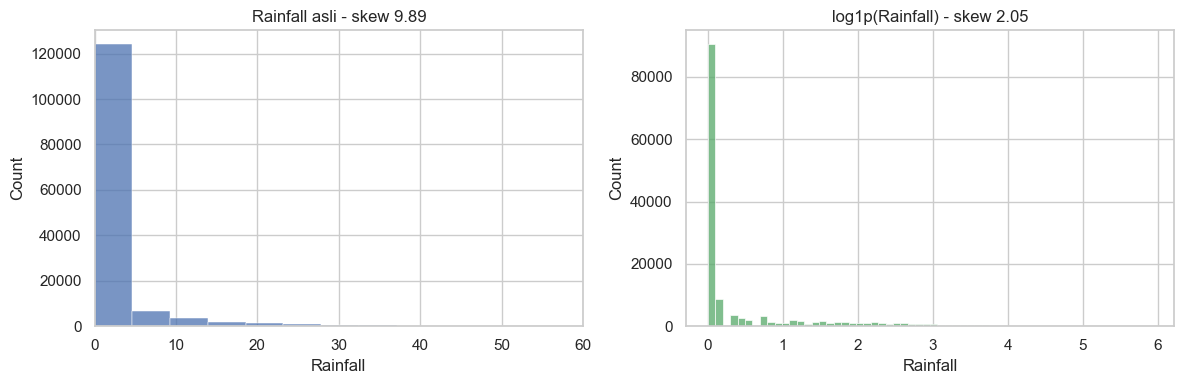

Panel kiri di-zoom ke 0-60 mm; nilai maksimum sebenarnya 371 mm.


In [54]:
# Gambar histogram Rainfall asli dan hasil log1p.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(r, bins=80, ax=axes[0], color="#4C72B0")
axes[0].set_title(f"Rainfall asli - skew {r.skew():.2f}")
axes[0].set_xlim(0, 60)
sns.histplot(np.log1p(r), bins=60, ax=axes[1], color="#55A868")
axes[1].set_title(f"log1p(Rainfall) - skew {np.log1p(r).skew():.2f}")
plt.tight_layout()
plt.show()
print(f"Panel kiri di-zoom ke 0-60 mm; nilai maksimum sebenarnya {r.max():.0f} mm.")

### 8.4 Distribusi Fitur Kunci Lainnya

Tidak semua kolom perlu ditransformasi. Kita lihat empat fitur penting:

- `Sunshine`
- `Humidity3pm`
- `MaxTemp`
- `WindGustSpeed`

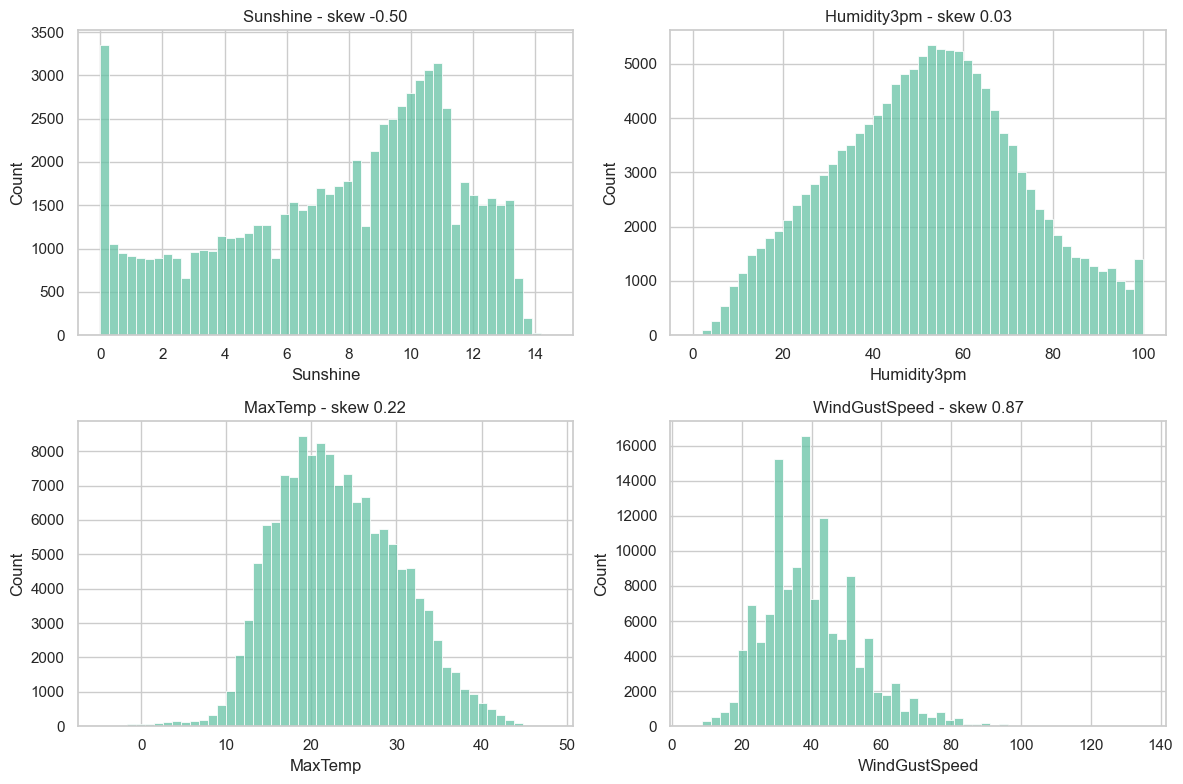

In [55]:
# Gambar distribusi empat fitur kunci.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["Sunshine", "Humidity3pm", "MaxTemp", "WindGustSpeed"]):
    sns.histplot(df[col].dropna(), bins=50, ax=ax)
    ax.set_title(f"{col} - skew {df[col].skew():.2f}")
plt.tight_layout()
plt.show()

### Cara Membaca Histogram Fitur Kunci

- **`Sunshine` bimodal**: ada dua puncak, sekitar 0–1 jam dan sekitar 10–11 jam.
  Ini bukan error; ini dua regime cuaca, yaitu mendung/hujan dan cerah.
- **`Humidity3pm` mendekati simetris**: menyebar di 10–100%.
- **`MaxTemp` mendekati normal**: tidak perlu transformasi.
- **`WindGustSpeed` menceng sedang ke kanan**: angin kencang jarang, tetapi itu sinyal cuaca ekstrem.

**Bimodal** = distribusi punya dua puncak.

### 8.5 Outlier Statistik ≠ Error Sensor

Boxplot menandai titik di luar 1,5 × IQR sebagai outlier.
Di data cuaca, outlier statistik belum tentu error.

Prinsip tim:

- Nilai **mustahil secara fisika** → sudah di-NaN di Bagian 7.
- Nilai **ekstrem tetapi valid** → dipertahankan karena kejadian iklim nyata.
- Tidak ada winsorize/clipping, karena memotong ekor berarti membuang kasus hujan
  ekstrem yang justru paling ingin diprediksi.

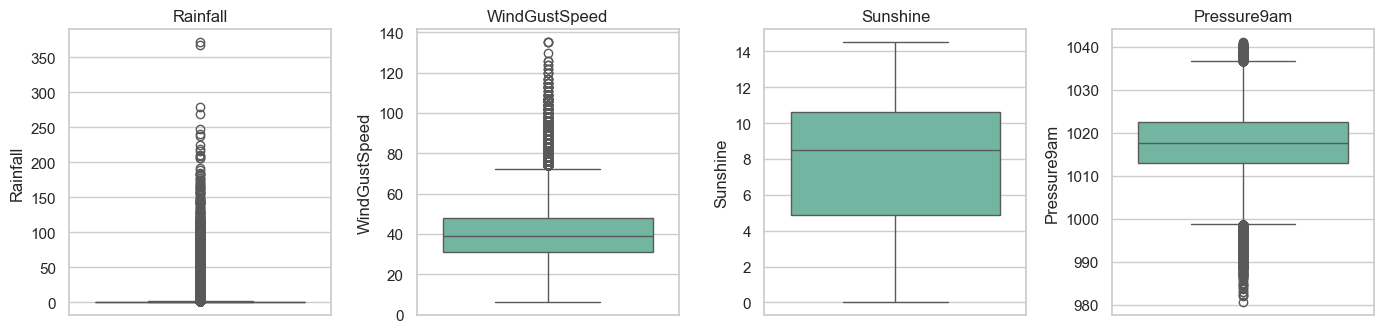

In [56]:
# Lihat outlier statistik memakai boxplot.
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, col in zip(axes, ["Rainfall", "WindGustSpeed", "Sunshine", "Pressure9am"]):
    sns.boxplot(y=df[col].dropna(), ax=ax).set(title=col)
plt.tight_layout()
plt.show()

In [57]:
# Tampilkan kejadian hujan sangat ekstrem yang tetap dipertahankan.
top_rain = df.loc[df["Rainfall"] > 200, ["Date", "Location", "Rainfall"]].sort_values("Rainfall", ascending=False)
display(top_rain)
print(f"Jumlah: {len(top_rain):,} baris | Maks: {top_rain['Rainfall'].max():.0f} mm")
print("Lokasi:", sorted(top_rain["Location"].unique()))

,Date,Location,Rainfall
68084,2009-11-07,CoffsHarbour,371.0
36837,2011-02-16,Darwin,367.6
51779,2009-01-12,Cairns,278.4
62506,2011-02-04,Cairns,268.6
52101,2015-02-08,Cairns,247.2
127041,2015-04-23,Newcastle,240.0
26769,2009-02-03,Townsville,236.8
3240,2016-01-06,Williamtown,225.0
93407,2016-06-05,CoffsHarbour,219.6
3634,2016-01-06,Newcastle,216.3


Jumlah: 14 baris | Maks: 371 mm
Lokasi: ['Cairns', 'CoffsHarbour', 'Darwin', 'Newcastle', 'Townsville', 'Williamtown']


### Cara Membaca Hujan Ekstrem

Ada 14 baris dengan `Rainfall > 200 mm`, maksimum 371 mm.
Semuanya berada di stasiun pesisir basah seperti Cairns, Darwin, CoffsHarbour,
Townsville, Newcastle, dan Williamtown.

Kesimpulan: ini kejadian iklim nyata (monsun/badai), bukan error sensor.
Karena itu nilai ekstrem dipertahankan. Skew-nya ditangani dengan `log1p` di pipeline,
bukan dengan memotong data.

### Decision Log Distribusi & Outlier

| Apa | Kenapa | Dampaknya |
|---|---|---|
| `Rainfall` skew 9,9 → `log1p` di pipeline | 9,9 → 2,1; membantu model linear, tree tetap invarian | transformasi ikut model, aman untuk aplikasi |
| `Sunshine` bimodal dibiarkan | dua puncak adalah regime cuaca nyata | sinyal prediktif kuat dipertahankan |
| Outlier hujan/angin ekstrem dipertahankan | kejadian iklim nyata | model tetap belajar kasus penting |
| Tanpa winsorize/clipping | memotong ekor membuang kasus yang ingin diprediksi | distribusi asli tetap terjaga |

## 9. Relasi Antar Kolom & Redundansi

> **Tahapan CRISP-DM:** Fase 2 — Data Understanding

Setelah data dibersihkan, kita periksa hubungan antar fitur.

Tujuan bagian ini:

1. Melihat korelasi antar kolom numerik.
2. Melihat kolom mana yang paling berhubungan dengan target.
3. Mengecek **redundansi**: apakah ada kolom yang isinya hampir sama sehingga bisa membebani model?

Istilah penting:

- **Korelasi Pearson (r)** = kekuatan hubungan linear dua kolom numerik, dari -1 sampai +1.
- **r positif** = jika satu naik, yang lain cenderung naik.
- **r negatif** = jika satu naik, yang lain cenderung turun.
- **Redundansi** = dua kolom membawa informasi yang hampir identik.
- **Multikolinearitas** = kondisi ketika banyak fitur saling berkorelasi sangat tinggi.

### 9.1 Heatmap Korelasi Antar Fitur Numerik

Heatmap di bawah menghitung korelasi Pearson pada kolom numerik data bersih.
`Evaporation` sudah dibuang. `RainTomorrow` bertipe category, jadi tidak ikut otomatis
di heatmap numerik; korelasinya terhadap target dihitung terpisah di 9.5.

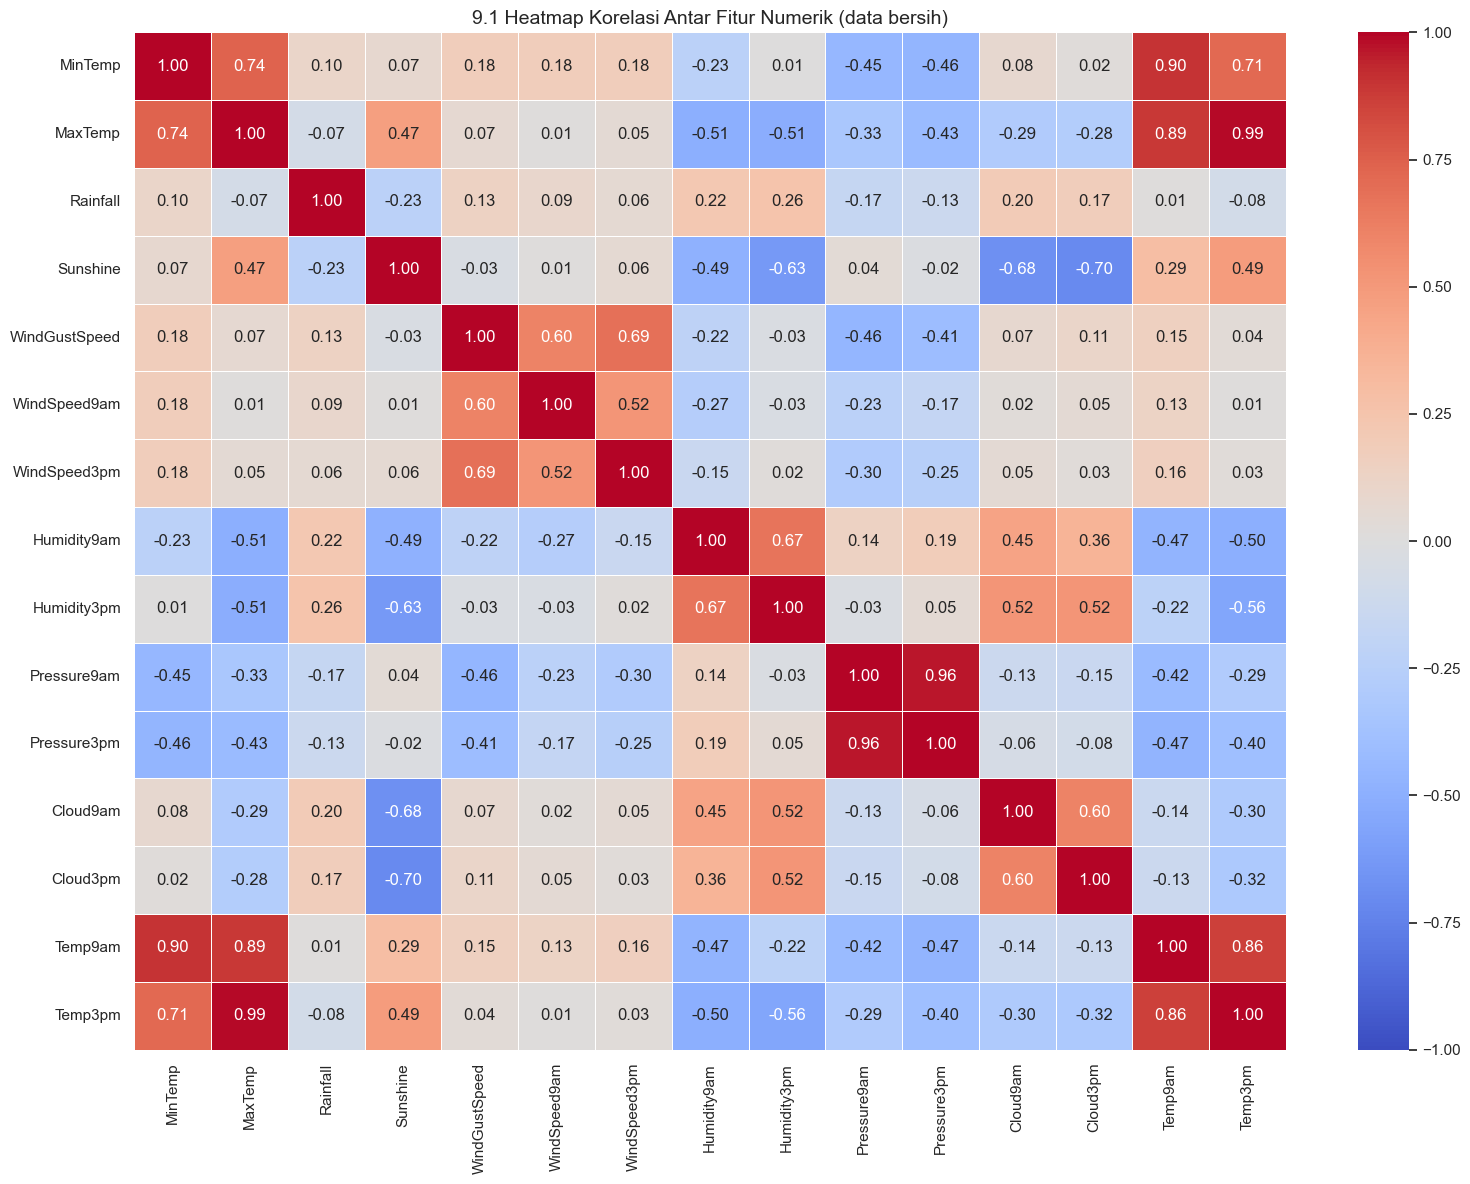

In [58]:
# Hitung dan gambar matriks korelasi antar fitur numerik.
corr_matrix = df[NUM_COLS].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("9.1 Heatmap Korelasi Antar Fitur Numerik (data bersih)", fontsize=14)
plt.tight_layout()
plt.show()

### Cara Membaca Heatmap

- Warna merah = korelasi positif.
- Warna biru = korelasi negatif.
- Angka 1,00 pada diagonal berarti kolom dibandingkan dengan dirinya sendiri.
- Makin dekat ke +1 atau -1, hubungan linearnya makin kuat.
- Heatmap hanya menangkap hubungan linear, bukan semua pola non-linear.

### 9.2 Pasangan Fitur yang Sangat Kuat

Kita filter pasangan dengan `|r| > 0.85`.
Ambang ini bukan hukum mutlak, hanya penyaring awal untuk diskusi redundansi.

In [59]:
# Kumpulkan pasangan kolom lalu saring korelasi sangat kuat.
semua_pair = []
for i, kolom_a in enumerate(NUM_COLS):
    for kolom_b in NUM_COLS[i + 1:]:
        r = corr_matrix.loc[kolom_a, kolom_b]
        semua_pair.append({"kolom_1": kolom_a, "kolom_2": kolom_b, "r": r})

pair_tab = pd.DataFrame(semua_pair)
redundan = pair_tab[pair_tab["r"].abs() > 0.85].sort_values("r", ascending=False)
display(redundan.round(3))

,kolom_1,kolom_2,r
26,MaxTemp,Temp3pm,0.985
90,Pressure9am,Pressure3pm,0.961
12,MinTemp,Temp9am,0.902
25,MaxTemp,Temp9am,0.887
104,Temp9am,Temp3pm,0.863


### Interpretasi Pasangan Positif Sangat Kuat

| Pasangan | r | Interpretasi |
|---|---:|---|
| `MaxTemp` & `Temp3pm` | 0.985 | suhu jam 3 sore hampir selalu dekat suhu maksimum harian |
| `Pressure9am` & `Pressure3pm` | 0.961 | tekanan udara sangat stabil dalam satu hari |
| `MinTemp` & `Temp9am` | 0.902 | suhu pagi dekat suhu minimum harian |
| `MaxTemp` & `Temp9am` | 0.887 | suhu pagi juga terkait suhu maksimum |
| `Temp9am` & `Temp3pm` | 0.863 | pola suhu pagi dan sore mirip |

Apakah semua harus dihapus? **Belum tentu.**

- Untuk model tree, korelasi tinggi antar fitur biasanya tidak merusak.
- `Temp3pm` justru punya korelasi target sekitar -0.189, sedikit lebih kuat daripada `MaxTemp` (-0.159).
- Menghapus fitur hanya karena korelasi antar fitur bisa membuang sinyal.
- Feature pruning harus diuji lewat cross-validation, bukan diputuskan dari heatmap saja.

In [60]:
# Tampilkan pasangan fitur yang berkorelasi negatif kuat.
negatif = pair_tab[pair_tab["r"] < -0.5].sort_values("r")
display(negatif.head(10).round(3))

,kolom_1,kolom_2,r
47,Sunshine,Cloud3pm,-0.704
46,Sunshine,Cloud9am,-0.676
43,Sunshine,Humidity3pm,-0.629
89,Humidity3pm,Temp3pm,-0.557
20,MaxTemp,Humidity3pm,-0.509
19,MaxTemp,Humidity9am,-0.505
83,Humidity9am,Temp3pm,-0.501


### Interpretasi Pasangan Negatif Kuat

Hubungan negatif di bawah masuk akal secara meteorologi:

| Pasangan | r | Interpretasi |
|---|---:|---|
| `Sunshine` & `Cloud3pm` | -0.704 | makin banyak awan sore, makin sedikit sinar matahari |
| `Sunshine` & `Cloud9am` | -0.676 | awan pagi mengurangi durasi sunshine |
| `Sunshine` & `Humidity3pm` | -0.629 | hari cerah cenderung lebih kering |
| `Humidity3pm` & `Temp3pm` | -0.557 | suhu sore naik, kelembapan relatif turun |
| `MaxTemp` & `Humidity3pm` | -0.509 | hari panas cenderung lebih kering |

Pasangan negatif ini bukan redundansi yang harus dibuang.
Justru hubungan ini bisa dipakai sebagai quality check dan sinyal cuaca.

In [61]:
# Fokus pada korelasi antar variabel kecepatan angin.
wind_cols = [c for c in NUM_COLS if "Wind" in c]
pasangan_angin = pair_tab[pair_tab["kolom_1"].isin(wind_cols) & pair_tab["kolom_2"].isin(wind_cols)]
display(pasangan_angin.sort_values("r", ascending=False).round(3))

,kolom_1,kolom_2,r
51,WindGustSpeed,WindSpeed3pm,0.686
50,WindGustSpeed,WindSpeed9am,0.605
60,WindSpeed9am,WindSpeed3pm,0.520


### Interpretasi Variabel Angin Numerik

- `WindGustSpeed` & `WindSpeed3pm`: sekitar 0.686.
- `WindGustSpeed` & `WindSpeed9am`: sekitar 0.605.
- `WindSpeed9am` & `WindSpeed3pm`: sekitar 0.520.

Korelasinya moderat, bukan sangat tinggi. Artinya masing-masing masih membawa informasi
berbeda: angin pagi, angin sore, dan hembusan puncak.

Ide fitur gabungan seperti `Avg_Wind_Speed` **ditunda** ke fase modeling.
Fitur baru hanya boleh masuk kalau terbukti menaikkan skor lewat cross-validation.

### 9.3 Redundansi `RainToday` dengan `Rainfall`

`RainToday` secara definisi diturunkan dari `Rainfall > 1 mm`.
Karena itu kita harus mengecek apakah labelnya konsisten 100% dengan aturan tersebut.

In [62]:
# Cek konsistensi RainToday terhadap aturan Rainfall lebih dari satu mm.
ada = df[["RainToday", "Rainfall"]].notna().all(axis=1)
aturan = df["Rainfall"] > 1
label = df["RainToday"] == "Yes"
cocok = ada & (aturan == label)
print(f"Dicek: {int(ada.sum()):,} | Cocok: {int(cocok.sum()):,} | Persentase: {cocok.sum()/ada.sum()*100:.1f}%")

subset = df[ada].copy()
subset["hujan_lebih_1mm"] = subset["Rainfall"] > 1
display(pd.crosstab(subset["hujan_lebih_1mm"], subset["RainToday"]))

Dicek: 140,787 | Cocok: 140,787 | Persentase: 100.0%


RainToday,No,Yes
hujan_lebih_1mm,,
False,109332,0
True,0,31455


### Interpretasi `RainToday`

- Pada baris yang `RainToday` dan `Rainfall` terisi, kecocokannya 100%.
- `RainToday` memang fitur turunan dari `Rainfall`.
- Secara teknis ini redundan.

Keputusan tim: **tetap pertahankan `RainToday`**.

Alasannya:

- mudah diinterpretasikan,
- murah untuk model tree,
- tidak menyebabkan leakage karena hujan hari ini diketahui saat prediksi dibuat,
- menghapusnya tidak otomatis membuat model lebih baik.

### 9.4 Redundansi Arah Angin

Tiga kolom arah angin adalah kategorikal, jadi korelasi Pearson tidak cocok.
Kita cek **tingkat kesepakatan label**: seberapa sering dua kolom arah angin bernilai sama.

In [63]:
# Hitung tingkat kesepakatan antar kolom arah angin.
pasangan = [("WindDir3pm", "WindGustDir"), ("WindDir9am", "WindDir3pm"), ("WindDir9am", "WindGustDir")]

for a, b in pasangan:
    ada = df[[a, b]].notna().all(axis=1)
    sama = ada & (df[a] == df[b])
    pct = sama.sum() / ada.sum() * 100
    print(f"{a} == {b}: dicek={int(ada.sum()):,}, sama={int(sama.sum()):,} ({pct:.1f}%)")

WindDir3pm == WindGustDir: dicek=131,911, sama=41,536 (31.5%)
WindDir9am == WindDir3pm: dicek=130,173, sama=23,235 (17.8%)
WindDir9am == WindGustDir: dicek=125,338, sama=28,053 (22.4%)


### Interpretasi Arah Angin

Tingkat kesepakatan hanya sekitar:

- `WindDir3pm` vs `WindGustDir`: 31,5%
- `WindDir9am` vs `WindDir3pm`: 17,9%
- `WindDir9am` vs `WindGustDir`: 22,4%

Artinya ketiga kolom arah angin **tidak redundan**. Arah angin berubah sepanjang hari,
dan arah gust bisa berbeda dari angin rata-rata. Semua kolom dipertahankan.

### 9.5 Korelasi dengan Target `RainTomorrow`

Heatmap numerik tidak otomatis memasukkan `RainTomorrow` karena target bertipe category.
Kita ubah sementara menjadi `y`:

- `Yes` → 1
- `No` → 0

Lalu hitung korelasi setiap fitur numerik terhadap `y`.

In [64]:
# Ubah target menjadi 1/0 dan hitung korelasi tiap fitur dengan target.
d = df.copy()
d["y"] = (d["RainTomorrow"] == "Yes").astype(int)
target_corr = d.corr(numeric_only=True)["y"].drop("y")
target_corr = target_corr.sort_values(key=abs, ascending=False)
display(target_corr.round(3).to_frame("korelasi_dgn_target"))

,korelasi_dgn_target
Sunshine,-0.451
Humidity3pm,0.446
Cloud3pm,0.382
Cloud9am,0.317
Humidity9am,0.257
Pressure9am,-0.246
Rainfall,0.239
WindGustSpeed,0.234
Pressure3pm,-0.226
Temp3pm,-0.189


### Interpretasi Korelasi Target

| Fitur | r | Arti |
|---|---:|---|
| `Sunshine` | -0.451 | makin cerah hari ini, makin kecil peluang hujan besok |
| `Humidity3pm` | +0.446 | makin lembap sore hari, makin besar peluang hujan besok |
| `Cloud3pm` | +0.382 | makin berawan sore hari, peluang hujan naik |
| `Cloud9am` | +0.317 | awan pagi juga sinyal hujan |
| `Humidity9am` | +0.257 | kelembapan pagi berguna, tetapi lebih lemah |
| `Pressure9am` | -0.246 | tekanan tinggi cenderung cuaca lebih stabil |
| `Rainfall` | +0.239 | hujan hari ini berguna, tetapi tidak menjamin besok hujan |
| `WindGustSpeed` | +0.234 | angin kencang berkaitan dengan sistem cuaca aktif |
| `Temp3pm` | -0.189 | sore lebih panas cenderung lebih kering |
| `MaxTemp` | -0.159 | sinyal suhu maksimum lebih lemah dari `Temp3pm` |

Korelasi linear tunggal tidak cukup karena hujan bersifat non-linear.
Namun sinyal `Sunshine`, `Humidity3pm`, dan `Cloud*` jelas kuat dan wajib dipertahankan.

### Decision Log Redundansi

| Apa | Kenapa | Dampaknya |
|---|---|---|
| Pasangan `|r| > 0.85` dicatat, tidak langsung dihapus | tree model toleran; `Temp3pm` masih punya sinyal target | tidak kehilangan informasi prematur |
| `RainToday` dipertahankan | 100% turunan `Rainfall > 1`, tetapi interpretable dan tidak leakage | fitur tetap murah dan mudah dijelaskan |
| Arah angin dipertahankan | kesepakatan label hanya 18–32% | ketiga kolom membawa informasi berbeda |
| Feature selection final ditunda ke modeling | keputusan harus diuji cross-validation | menghindari spekulasi |

## 10. Data Siap Pakai

> **Tahapan CRISP-DM:** Fase 3 — Data Preparation

Bagian ini adalah snapshot `df` setelah:

- transformasi tipe data,
- drop `Evaporation`,
- drop baris tanpa `RainTomorrow`,
- koreksi nilai tidak valid menjadi NaN.

Data inilah yang masuk ke Bagian 11, lalu ke fase modeling.

In [65]:
# Tampilkan bentuk dan memori data siap pakai.
print(f"Bentuk akhir   : {len(df):,} baris x {df.shape[1]} kolom")
print(f"Memori         : {df.memory_usage(deep=True).sum()/1e6:.1f} MB")
print(f"Target         : {dict(df['RainTomorrow'].value_counts())}")
print("Kolom dibuang  : Evaporation")

Bentuk akhir   : 142,193 baris x 22 kolom
Memori         : 24.4 MB
Target         : {'No': np.int64(110316), 'Yes': np.int64(31877)}
Kolom dibuang  : Evaporation


In [66]:
# Tampilkan kolom yang masih memiliki NaN.
total_nan = int(df.isna().sum().sum())
print(f"Total sel NaN: {total_nan:,} ({total_nan/df.size*100:.1f}%)")

nan_sisa = df.isna().sum()
display(nan_sisa[nan_sisa > 0].sort_values(ascending=False).to_frame("n_nan"))

Total sel NaN: 256,263 (8.2%)


,n_nan
Sunshine,67816
Cloud3pm,57094
Cloud9am,53657
Pressure9am,14014
Pressure3pm,13981
WindDir9am,10013
WindGustDir,9330
WindGustSpeed,9275
WindDir3pm,3778
Humidity3pm,3610


### Cara Membaca Snapshot

- Bentuk data akhir: 142.193 baris × 22 kolom.
- Komposisi kolom: `Date` + 15 numerik + 5 kategorikal fitur + `RainTomorrow`.
- NaN sengaja dibiarkan karena bersifat struktural atau hasil koreksi validitas.
- XGBoost dapat memakai NaN native.
- RandomForest/LogisticRegression akan memakai imputasi **di dalam pipeline**, bukan di dataframe global.

## 11. Data Preparation & Split

> **Tahapan CRISP-DM:** Fase 3 — Data Preparation

Bagian ini menutup checklist tim item 10–15:

10. Feature engineering
11. Encoding
12. Normalisasi/standardisasi
13. Feature selection
14. Penanganan imbalance
15. Data split

**Prinsip anti-leakage:** semua transformasi yang belajar dari data — imputer, scaler,
encoder — hanya boleh di-fit pada data train. Karena itu pemasangannya dilakukan di
`sklearn.Pipeline` pada fase modeling, bukan pada dataframe global di notebook ini.

### 11.1 Feature Engineering — `Month` & `Season`

**Feature engineering** = membuat kolom baru dari kolom yang sudah ada.

`Date` tidak bisa langsung jadi fitur karena nilainya hampir selalu unik.
Yang berguna adalah pola musimannya:

- `Month` = bulan 1–12.
- `Season` = kelompok musim:
  - 0 = Des–Feb
  - 1 = Mar–Mei
  - 2 = Jun–Agu
  - 3 = Sep–Nov

`Year` sengaja tidak dipakai. Data berakhir 2017, jadi model tidak boleh mengandalkan
tren tahun yang tidak akan terulang di produksi.

Logika ini identik dengan `src/train.py`.

In [67]:
# Buat fitur musiman dari tanggal: Month dan Season.
df_prep = df.copy()
df_prep["Month"] = df_prep["Date"].dt.month
df_prep["Season"] = df_prep["Month"].map(lambda m: (m % 12) // 3)
print(f"Kolom: {df.shape[1]} -> {df_prep.shape[1]} (+Month, +Season)")

Kolom: 22 -> 24 (+Month, +Season)


In [68]:
# Cek hasil feature engineering musiman pada beberapa baris.
display(df_prep[["Date", "Month", "Season"]].head())
print(df_prep["Season"].value_counts().sort_index())

,Date,Month,Season
0,2008-12-16,12,0
1,2010-02-10,2,0
2,2010-02-12,2,0
6,2013-06-05,6,2
9,2009-10-05,10,3


Season
0    34256
1    37397
2    35930
3    34610
Name: count, dtype: int64


In [69]:
# Hitung peluang hujan besok untuk setiap bulan.
df_prep["y"] = (df_prep["RainTomorrow"] == "Yes").astype(int)
rate_bulan = df_prep.groupby("Month")["y"].mean() * 100
print(rate_bulan.round(1).to_string())

Month
1     19.3
2     21.0
3     21.3
4     21.8
5     22.5
6     26.2
7     26.9
8     25.3
9     23.0
10    19.6
11    21.3
12    20.8

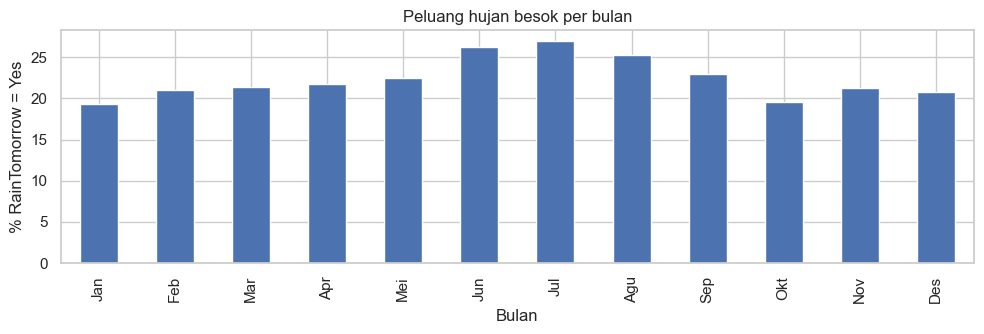

In [70]:
# Visualisasikan peluang hujan per bulan.
fig, ax = plt.subplots(figsize=(10, 3.5))
rate_bulan.plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_xlabel("Bulan")
ax.set_ylabel("% RainTomorrow = Yes")
ax.set_title("Peluang hujan besok per bulan")
ax.set_xticks(range(12))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"])
plt.tight_layout()
plt.show()

### Cara Membaca Bukti Musiman

Kalau peluang hujan per bulan hampir seragam, fitur `Month` tidak terlalu berguna.
Jika batang naik-turun, ada pola musiman yang bisa dipelajari model.

Di Australia, pola hujan berbeda menurut wilayah: musim dingin lebih basah di selatan,
sedangkan monsun Nov–Mar kuat di utara. Karena itu `Month` dan `Season` dipertahankan.

Ide feature engineering lain, misalnya `Avg_Wind_Speed`, selisih tekanan, atau rasio
kelembapan pagi–sore, **ditunda** ke fase modeling. Fitur baru hanya masuk jika terbukti
membantu lewat cross-validation.

### 11.2 Encoding — OneHot, bukan Label

**Encoding** = mengubah kolom non-numerik menjadi bentuk yang bisa dibaca model.

Lima fitur kategorikal final:

- `Location`
- `WindGustDir`
- `WindDir9am`
- `WindDir3pm`
- `RainToday`

Semuanya nominal, artinya tidak punya urutan matematis.
`OneHotEncoder` membuat satu kolom binary untuk setiap kategori.

Target `RainTomorrow` dipetakan manual:

- `Yes` → 1
- `No` → 0

In [71]:
# Definisikan fitur kategorikal dan hitung jumlah kategori tiap kolom.
CAT_FEATS = ["Location", "WindGustDir", "WindDir9am", "WindDir3pm", "RainToday"]
jumlah_kategori = df_prep[CAT_FEATS].nunique().rename("jumlah_kategori")
display(jumlah_kategori.to_frame())

,jumlah_kategori
Location,49
WindGustDir,16
WindDir9am,16
WindDir3pm,16
RainToday,2


In [72]:
# Hitung jumlah kolom model sebelum dan sesudah one-hot encoding.
total_onehot = int(jumlah_kategori.sum())
num_after_fe = len(NUM_COLS) + 2

print(f"Kolom kategori sebelum one-hot : {len(CAT_FEATS)}")
print(f"Total kolom hasil one-hot      : {total_onehot}")
print(f"Kolom numerik setelah FE       : {num_after_fe}")
print(f"Total fitur model              : {total_onehot + num_after_fe}")

Kolom kategori sebelum one-hot : 5
Total kolom hasil one-hot      : 99
Kolom numerik setelah FE       : 17
Total fitur model              : 116


### Cara Membaca Encoding

- Ada 99 kolom hasil one-hot dari 5 fitur kategorikal.
- Ada 17 fitur numerik setelah menambah `Month` dan `Season`.
- Total fitur sebelum model = 116 kolom.
- One-hot dilakukan di dalam pipeline, bukan manual di notebook, agar kategori yang
  dipelajari hanya berasal dari data train.

### 11.3 Normalisasi & Standardisasi

**Normalisasi/standardisasi** = menyamakan skala fitur.

| Model | Butuh scaling? | Alasan |
|---|---|---|
| LogisticRegression | Ya | koefisien dan konvergensi sensitif terhadap skala |
| RandomForest / XGBoost | Tidak | split pohon hanya memakai urutan nilai |

Keputusan tim: `StandardScaler` dipasang seragam di pipeline.
Scaler wajib untuk LogisticRegression dan tidak merusak tree model.
`log1p(Rainfall)` juga dipasang sebagai step pipeline.

**Titik kritis leakage:** mean dan std hanya boleh dihitung dari `X_train`.
Kalau dihitung dari seluruh data, informasi test bocor ke training dan metrik menjadi
terlalu optimis.

In [73]:
# Contoh mean dan std yang nanti dipelajari StandardScaler di pipeline.
contoh = df_prep[["Rainfall", "Humidity3pm", "Pressure3pm"]].describe().loc[["mean", "std"]]
display(contoh.round(2))
print("Dua angka per kolom (mean & std) inilah yang nanti dipelajari StandardScaler.")
print("Di fase modeling: fit hanya pada X_train, lalu transform X_test.")
print("Angka di atas dihitung dari seluruh data HANYA untuk ilustrasi.")

,Rainfall,Humidity3pm,Pressure3pm
mean,2.35,51.48,1015.26
std,8.47,20.80,7.04


Dua angka per kolom (mean & std) inilah yang nanti dipelajari StandardScaler.
Di fase modeling: fit hanya pada X_train, lalu transform X_test.
Angka di atas dihitung dari seluruh data HANYA untuk ilustrasi.


### 11.4 Feature Selection

| Aksi | Kolom | Alasan |
|---|---|---|
| Diekstrak lalu tidak dipakai langsung | `Date` | sudah menjadi `Month` / `Season` |
| Tidak dipakai | `Year` | risiko ekstrapolasi tren masa depan |
| Drop | `Evaporation` | missing 43%, sinyal terlemah |
| Jadi label | `RainTomorrow` | target → `y` |
| Pertahankan | 22 fitur | 17 numerik + 5 kategorikal |

Multikolinearitas tidak dihapus sekarang. Keputusan pruning ditunda ke fase modeling
dan harus diuji lewat cross-validation.

In [74]:
# Definisikan daftar fitur final sebelum encoding.
NUM_FEATS = NUM_COLS + ["Month", "Season"]
CAT_FEATS = ["Location", "WindGustDir", "WindDir9am", "WindDir3pm", "RainToday"]
FEATURES = NUM_FEATS + CAT_FEATS

print(f"{len(NUM_FEATS)} numerik : {NUM_FEATS}")
print(f"{len(CAT_FEATS)} kategori : {CAT_FEATS}")
print(f"Total {len(FEATURES)} fitur sebelum one-hot")

17 numerik : ['MinTemp', 'MaxTemp', 'Rainfall', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'Month', 'Season']
5 kategori : ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']
Total 22 fitur sebelum one-hot


### 11.5 Class Imbalance

**Class imbalance** = jumlah kelas target tidak seimbang.
Di sini sekitar 77,6% `No` dan 22,4% `Yes`.

Keputusan tim:

- Metrik pemilihan model memakai F1, didukung PR-AUC dan ROC-AUC.
- Pakai **class weight**, bukan SMOTE.
  - LogisticRegression/RandomForest: `class_weight="balanced"`.
  - XGBoost: `scale_pos_weight = jumlah negatif / jumlah positif`.
- SMOTE ditolak karena sampel sintetis pada data deret waktu berisiko melintasi batas
  split dan merusak pola musiman.
- Threshold default 0,5; threshold optimal dicari di fase evaluasi.

In [75]:
# Hitung proporsi kelas dan scale_pos_weight untuk XGBoost.
pos = int(df_prep["y"].sum())
neg = int((df_prep["y"] == 0).sum())

print(f"Yes = {pos:,} ({pos/(pos+neg)*100:.1f}%)")
print(f"No  = {neg:,} ({neg/(pos+neg)*100:.1f}%)")
print(f"scale_pos_weight (XGBoost) = {neg/pos:.2f}")
print(f"Baseline 'selalu jawab No' = akurasi {neg/(pos+neg)*100:.1f}%")

Yes = 31,877 (22.4%)
No  = 110,316 (77.6%)
scale_pos_weight (XGBoost) = 3.46
Baseline 'selalu jawab No' = akurasi 77.6%


### 11.6 Data Split — Time-Based 80/20

Model akan dipakai memprediksi masa depan. Karena itu split dilakukan kronologis:

- 80% data paling awal = train.
- 20% data paling akhir = test.
- Tanpa shuffle.

Hasil yang diharapkan:

- Train: 113.754 baris.
- Test: 28.439 baris.
- Batas tanggal: 2015-11-10.
- `%Yes` train dan test stabil di sekitar 22%.

Split ini identik dengan `time_split()` di `src/train.py`.

In [76]:
# Urutkan data menurut waktu lalu split 80 persen train dan 20 persen test.
df_prep = df_prep.sort_values("Date").reset_index(drop=True)
split_idx = int(len(df_prep) * 0.8)
train = df_prep.iloc[:split_idx]
test = df_prep.iloc[split_idx:]

print(f"Train : {len(train):,} baris | {train['Date'].min().date()} s.d. {train['Date'].max().date()}")
print(f"Test  : {len(test):,} baris | {test['Date'].min().date()} s.d. {test['Date'].max().date()}")

Train : 113,754 baris | 2007-11-01 s.d. 2015-11-10
Test  : 28,439 baris | 2015-11-10 s.d. 2017-06-25


In [77]:
# Pastikan tidak ada tanggal train yang melewati batas test.
assert train["Date"].max() <= test["Date"].min(), "LEAK: ada tanggal train melewati batas test!"
print("Tidak ada tanggal train yang melewati batas test.")

if train["Date"].max() == test["Date"].min():
    print("Tanggal batas sama karena beberapa stasiun pada hari itu terpotong dua.")
    print("Ini bukan kebocoran informasi lintas waktu.")

Tidak ada tanggal train yang melewati batas test.
Tanggal batas sama karena beberapa stasiun pada hari itu terpotong dua.
Ini bukan kebocoran informasi lintas waktu.


In [78]:
# Bandingkan proporsi target pada train dan test.
print(f"Train %Yes = {train['y'].mean()*100:.1f}")
print(f"Test  %Yes = {test['y'].mean()*100:.1f}")

selisih = abs(train["y"].mean() - test["y"].mean()) * 100
print(f"Selisih = {selisih:.1f} poin persen")

Train %Yes = 22.4
Test  %Yes = 22.3
Selisih = 0.1 poin persen


### Cara Membaca Split

- Train lebih dulu, test lebih akhir.
- Tidak ada tanggal train yang melewati batas test.
- Proporsi `Yes` di train dan test hampir sama, jadi split sehat.
- Kalau proporsinya jauh berbeda, perbandingan model bisa bias karena split, bukan karena model.

Langkah berikutnya di fase modeling:

1. Fit pipeline hanya pada `X_train`.
2. Cross-validation dan tuning.
3. Bandingkan LR/RF/XGBoost.
4. Sentuh `X_test` sekali di akhir untuk evaluasi final.

### Status Checklist Persiapan Data (item 10–15)

| Item | Status | Implementasi |
|---|---|---|
| 10. Feature engineering | Selesai | `Month`, `Season`; ide lain menunggu validasi CV |
| 11. Encoding | Selesai | OneHot di pipeline; target `Yes/No` → 1/0 |
| 12. Normalisasi/standardisasi | Selesai | `StandardScaler` + `log1p(Rainfall)` di pipeline |
| 13. Feature selection | Selesai | 22 fitur final; pruning kolinear ditunda ke CV |
| 14. Imbalance | Selesai | class weight, `scale_pos_weight`, F1 sebagai metrik utama |
| 15. Data split | Selesai | time-based 80/20 tanpa shuffle |

## 12. Ringkasan & Decision Log

> **Tahapan CRISP-DM:** Fase 1–3 (penutup & handoff)

Bagian ini merangkum semua keputusan penting dengan pola:

**Apa → Kenapa → Dampaknya**

Bentuk data akhir sebelum feature engineering: **142.193 baris × 22 kolom**.
Setelah `Month`, `Season`, dan `y` ditambahkan, dataframe persiapan memiliki kolom
tambahan, tetapi fitur model sebelum one-hot tetap **22 fitur** (17 numerik + 5 kategorikal).

### Decision Log 1: Tipe Data & Missing Value

| Apa | Kenapa | Dampaknya |
|---|---|---|
| `Date` → `datetime64` | 0 gagal parse; perlu urutan waktu dan fitur musiman | time-based split aman |
| 6 kolom teks → `category` | label nominal, hemat memori | analisis lebih cepat dan konsisten |
| 15 kolom numerik tetap `float64` | mengandung NaN | tidak memaksa integer yang tidak realistis |
| Drop `Evaporation` | missing 43%, sinyal terlemah | dataset lebih ringan tanpa rugi performa |
| Drop baris tanpa `RainTomorrow` | supervised learning butuh label | 3.267 baris dibuang, sisa 142.193 |
| Biarkan NaN sisa | XGBoost native NaN; imputasi global tidak lebih baik | tidak menciptakan informasi palsu |
| Tanpa indikator missing | benchmark tidak menambah sinyal | pipeline lebih sederhana |

### Decision Log 2: Validitas & Outlier

| Apa | Kenapa | Dampaknya |
|---|---|---|
| `Temp3pm` selisih > 1°C → NaN | 539 baris, indikasi error sensor | suhu sore lebih dapat dipercaya |
| `Temp3pm` selisih ≤ 1°C dibiarkan | 679 baris, artefak pembulatan/sensor | tidak membuang data wajar |
| `Temp9am` > 1°C → NaN | 2 baris error | suhu pagi lebih dapat dipercaya |
| `Temp9am` ≤ 1°C dibiarkan | 14 baris artefak ukur | tidak over-cleaning |
| Gust < angin rata-rata → NaN | 5 baris mustahil secara definisi | fitur angin lebih valid |
| `WindSpeed9am` 130 km/j → NaN | 1 baris error ekstrem | mencegah outlier palsu |
| `Rainfall > 200 mm` dipertahankan | 14 kejadian iklim nyata, maks 371 mm | model tetap belajar hujan ekstrem |

### Decision Log 3: Distribusi, Relasi & Redundansi

| Apa | Kenapa | Dampaknya |
|---|---|---|
| `log1p(Rainfall)` di pipeline | skew 9,9 → 2,1 | model linear terbantu, tree tetap aman |
| `Sunshine` bimodal dipertahankan | dua puncak = regime cuaca nyata | sinyal prediktif kuat tidak hilang |
| Outlier valid tidak di-clip | hujan/angin ekstrem adalah kejadian nyata | evaluasi tidak kehilangan kasus penting |
| Pair `|r| > 0.85` dicatat | `MaxTemp↔Temp3pm`, `Pressure9am↔Pressure3pm`, dll. | kandidat pruning, bukan keputusan final |
| `RainToday` dipertahankan | 100% cocok dengan `Rainfall > 1`, interpretable | redundansi diterima karena murah |
| Arah angin dipertahankan | kesepakatan hanya 18–32% | bukan kolom redundan |

### Decision Log 4: Preparation, Imbalance & Split

| Apa | Kenapa | Dampaknya |
|---|---|---|
| Tambah `Month` & `Season` | hujan Australia punya pola musiman | model bisa belajar musim |
| Tidak pakai `Year` | data berakhir 2017, tren tahun tidak bisa diekstrapolasi | mencegah ketergantungan palsu |
| OneHot untuk 5 kolom kategori | label nominal, label encoding membuat urutan palsu | 99 kolom one-hot |
| StandardScaler + log1p di pipeline | LR butuh skala; fit hanya dari train | mencegah leakage |
| Class weight, bukan SMOTE | data deret waktu; SMOTE berisiko leakage temporal | imbalance tertangani aman |
| `scale_pos_weight` 3,46 | No/Yes sekitar 77,6/22,4 | XGBoost lebih memperhatikan kelas hujan |
| Time-based split 80/20 | prediksi masa depan | 113.754 train / 28.439 test |
| `%Yes` train-test stabil | 22,4% vs 22,3% | split sehat |
| `src/train.py` disinkronkan | cleaning notebook = pipeline training | satu sumber kebenaran |

### Hasil Akhir yang Harus Diingat

- Baris awal: **145.460**.
- Baris setelah drop target NaN: **142.193**.
- Kolom dibuang permanen: **`Evaporation`**.
- Cleaning validitas final: **`Temp3pm 539`, `Temp9am 2`, `WindGustSpeed 5`, `WindSpeed9am 1`**.
- Total NaN final setelah validitas: **256.263 sel**.
- Fitur model sebelum one-hot: **22 fitur** (17 numerik + 5 kategorikal).
- Total kolom setelah one-hot: **116 fitur**.
- Split: **113.754 train / 28.439 test**, batas **2015-11-10**.
- `scale_pos_weight`: **3,46**.

**Langkah berikutnya:** fase modeling. Pipeline di-fit hanya pada train, dilakukan
cross-validation dan tuning, lalu `X_test` disentuh sekali untuk evaluasi final.